# DeliveryIQ — Notebook 01: Data Exploration

**Project:** DeliveryIQ — Intelligent Shipment Analytics & Delay Prediction (Fundamentals of Data Science)
**Notebook:** `notebooks/01_data_exploration.ipynb`  |  **Data:** Olist Brazilian E-Commerce Public Dataset

## Objectives
1. Understand the raw Olist tables: schemas, keys, how they join, and the cardinality of orders, items and sellers.
2. Audit data quality (missing values, duplicates, timestamp problems, logical anomalies, order status) and justify every cleaning decision.
3. Show, on real example orders, how raw columns become the engineered columns used by the dashboard and the model
   (`delivery_duration_days`, `delivery_delay_days`, `is_late`, `processing_days`, `estimated_delivery_days`, ...).
4. Explore delivery performance (duration, delay, lateness over time, by state, category, weight, freight, seller processing time).
5. Separate **purchase-time** features from **after-the-fact** columns, and explain why mixing them is data leakage.

## Dataset provenance
*Brazilian E-Commerce Public Dataset by Olist* (Kaggle: <https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce>).
It contains roughly 100,000 orders placed on the Olist marketplace between 2016 and 2018, with items, sellers, customers,
products, reviews and a Portuguese-to-English category translation. The raw CSVs live in `data/raw/`; the cleaned analysis tables
are produced by `src/preprocessing.py` into `data/processed/`. Customer and seller identifiers in the source are anonymised by Olist.
The dataset has **no** courier, GPS, weather, or carrier-route information; nothing like that is used or invented here.

## How to run
From the project root (or from `notebooks/`), with the project virtual environment:

```bash
.venv/bin/python -m src.preprocessing        # (re)builds data/processed/*.parquet and the quality report
.venv/bin/jupyter lab notebooks/01_data_exploration.ipynb
```
The notebook finds the project root automatically. Figures are also saved as PNG files in `reports/figures/`.
It runs top-to-bottom in well under two minutes.

## Contents
1. Dataset understanding &nbsp;·&nbsp; 2. Data quality & cleaning decisions &nbsp;·&nbsp; 3. Feature-engineering walk-through &nbsp;·&nbsp;
4. Exploratory analysis &nbsp;·&nbsp; 5. Predictive vs descriptive feature sets (leakage) &nbsp;·&nbsp; 6. Key takeaways, limitations, next steps

**Conventions used throughout.** Rates always come with their sample size `n`. "Associated with" never means "caused by".
Analyses that use information only available after the purchase are labelled **RETROSPECTIVE**.
A segment is called *reliable* only if it has at least `config.DEFAULT_MIN_ORDERS` (= 100) orders.

In [1]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score

# Resolve the project root whether the notebook is run from notebooks/ or from the root.
_here = Path.cwd().resolve()
ROOT = next((p for p in [_here, *_here.parents] if (p / "src" / "config.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from inside the DeliveryIQ project folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config
from src.preprocessing import load_raw, build_orders_table, load_processed

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

P = config.PALETTE
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 110, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": P["slate_light"], "axes.labelcolor": P["slate"],
    "axes.titlecolor": P["navy"], "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": P["border"], "grid.linewidth": 0.7,
    "axes.axisbelow": True, "xtick.color": P["slate"], "ytick.color": P["slate"],
    "font.size": 10, "legend.frameon": False,
})
FIG_DIR = config.FIGURES_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_show(fig, name: str) -> None:
    """Save a figure as PNG under reports/figures/ (for GitHub) and display it inline."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


def wilson(k, n, z: float = 1.96):
    """Vectorised Wilson score interval for proportions (NaN where n == 0)."""
    k = np.asarray(k, dtype=float); n = np.asarray(n, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = k / n
        denom = 1 + z**2 / n
        centre = (p + z**2 / (2 * n)) / denom
        half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


MIN_N = config.DEFAULT_MIN_ORDERS
print(f"Project root : {ROOT}")
print(f"Figures dir  : {FIG_DIR.relative_to(ROOT)}")
print(f"Minimum sample for a 'reliable' segment: n >= {MIN_N}")

Project root : /Users/keertika/Desktop/fods
Figures dir  : reports/figures
Minimum sample for a 'reliable' segment: n >= 100


## 1. Dataset understanding

This notebook is *exploration*, so the raw files are read here directly with `pandas` (default type inference) to show their
true schema. The production pipeline (`src.preprocessing.load_raw`) reads everything as text and parses explicitly; we call that
real pipeline later in section 2 and reconcile it with what we find here.

In [2]:
raw_dir = config.RAW_DIR
files = {**config.REQUIRED_RAW_FILES, **config.OPTIONAL_RAW_FILES}
# Plain pandas read (default dtype inference) -- this is exploration, not the pipeline.
tables = {name: pd.read_csv(raw_dir / fn) for name, fn in files.items()}
orders, items, customers, sellers, products = (tables[k] for k in
                                               ["orders", "items", "customers", "sellers", "products"])
reviews, translation = tables["reviews"], tables["category_translation"]

overview = pd.DataFrame({
    "file": [files[k] for k in tables],
    "rows": [len(t) for t in tables.values()],
    "columns": [t.shape[1] for t in tables.values()],
    "size_MB": [round((raw_dir / files[k]).stat().st_size / 1e6, 2) for k in tables],
}, index=list(tables))
overview

,file,rows,columns,size_MB
orders,olist_orders_dataset.csv,99441,8,17.650
items,olist_order_items_dataset.csv,112650,7,15.440
customers,olist_customers_dataset.csv,99441,5,9.030
sellers,olist_sellers_dataset.csv,3095,4,0.170
products,olist_products_dataset.csv,32951,9,2.380
reviews,olist_order_reviews_dataset.csv,99224,7,14.450
category_translation,product_category_name_translation.csv,71,2,0.000


In [3]:
for name in ["orders", "items"]:
    print(f"===== {name} =====")
    tables[name].info()
    print()

===== orders =====
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB

===== items =====
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str 

In [4]:
for name in ["customers", "sellers", "products", "reviews", "category_translation"]:
    print(f"===== {name} =====")
    tables[name].info()
    print()

===== customers =====
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 11.0 MB

===== sellers =====
<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: int64(1), str(3)
memory usage: 23

In [5]:
orders.head(3).T

,0,1,2
order_id,e481f51cbdc54678b7cc49136f2d6af7,53cdb2fc8bc7dce0b6741e2150273451,47770eb9100c2d0c44946d9cf07ec65d
customer_id,9ef432eb6251297304e76186b10a928d,b0830fb4747a6c6d20dea0b8c802d7ef,41ce2a54c0b03bf3443c3d931a367089
order_status,delivered,delivered,delivered
order_purchase_timestamp,2017-10-02 10:56:33,2018-07-24 20:41:37,2018-08-08 08:38:49
order_approved_at,2017-10-02 11:07:15,2018-07-26 03:24:27,2018-08-08 08:55:23
order_delivered_carrier_date,2017-10-04 19:55:00,2018-07-26 14:31:00,2018-08-08 13:50:00
order_delivered_customer_date,2017-10-10 21:25:13,2018-08-07 15:27:45,2018-08-17 18:06:29
order_estimated_delivery_date,2017-10-18 00:00:00,2018-08-13 00:00:00,2018-09-04 00:00:00


In [6]:
display(items.head(3).T)
display(products.head(3).T)
display(reviews.drop(columns=["review_comment_message"]).head(3).T)

,0,1,2
order_id,00010242fe8c5a6d1ba2dd792cb16214,00018f77f2f0320c557190d7a144bdd3,000229ec398224ef6ca0657da4fc703e
order_item_id,1,1,1
product_id,4244733e06e7ecb4970a6e2683c13e61,e5f2d52b802189ee658865ca93d83a8f,c777355d18b72b67abbeef9df44fd0fd
seller_id,48436dade18ac8b2bce089ec2a041202,dd7ddc04e1b6c2c614352b383efe2d36,5b51032eddd242adc84c38acab88f23d
shipping_limit_date,2017-09-19 09:45:35,2017-05-03 11:05:13,2018-01-18 14:48:30
price,58.900,239.900,199.000
freight_value,13.290,19.930,17.870


,0,1,2
product_id,1e9e8ef04dbcff4541ed26657ea517e5,3aa071139cb16b67ca9e5dea641aaa2f,96bd76ec8810374ed1b65e291975717f
product_category_name,perfumaria,artes,esporte_lazer
product_name_lenght,40.000,44.000,46.000
product_description_lenght,287.000,276.000,250.000
product_photos_qty,1.000,1.000,1.000
product_weight_g,225.000,"1,000.000",154.000
product_length_cm,16.000,30.000,18.000
product_height_cm,10.000,18.000,9.000
product_width_cm,14.000,20.000,15.000


,0,1,2
review_id,7bc2406110b926393aa56f80a40eba40,80e641a11e56f04c1ad469d5645fdfde,228ce5500dc1d8e020d8d1322874b6f0
order_id,73fc7af87114b39712e6da79b0a377eb,a548910a1c6147796b98fdf73dbeba33,f9e4b658b201a9f2ecdecbb34bed034b
review_score,4,5,5
review_comment_title,NaN,NaN,NaN
review_creation_date,2018-01-18 00:00:00,2018-03-10 00:00:00,2018-02-17 00:00:00
review_answer_timestamp,2018-01-18 21:46:59,2018-03-11 03:05:13,2018-02-18 14:36:24


### Entity-relationship structure

```
 customers (customer_id PK, customer_unique_id, zip, city, state)
        │ 1
        │            one customer_id appears in exactly one order
        │ N (1 in practice)
 orders (order_id PK, customer_id FK, order_status, 5 timestamps)
        │ 1                                            │ 1
        │ N                                            │ N
 order_items (order_id FK + order_item_id PK,          order_reviews (review_id, order_id FK, score, dates, comments)
              product_id FK, seller_id FK, price, freight_value, shipping_limit_date)
        │ N                      │ N
        │ 1                      │ 1
 products (product_id PK, category [PT], weight, L/H/W)     sellers (seller_id PK, zip, city, state)
        │ N
        │ 1
 category_translation (product_category_name [PT] -> product_category_name_english)
```

Join keys: `orders.customer_id → customers.customer_id`, `order_items.order_id → orders.order_id`, `order_items.product_id → products.product_id`,
`order_items.seller_id → sellers.seller_id`, `order_reviews.order_id → orders.order_id`, `products.product_category_name → category_translation.product_category_name`.
The cells below verify these relationships on the data instead of assuming them.

In [7]:
def coverage(child: pd.Series, parent: pd.Series) -> dict:
    """Share of non-null child keys that exist in the parent key set."""
    c = child.dropna()
    return {"child_rows": len(c), "found_in_parent": int(c.isin(set(parent)).sum()),
            "orphans": int((~c.isin(set(parent))).sum())}

checks = {
    "orders.customer_id -> customers.customer_id": coverage(orders["customer_id"], customers["customer_id"]),
    "items.order_id -> orders.order_id": coverage(items["order_id"], orders["order_id"]),
    "items.product_id -> products.product_id": coverage(items["product_id"], products["product_id"]),
    "items.seller_id -> sellers.seller_id": coverage(items["seller_id"], sellers["seller_id"]),
    "reviews.order_id -> orders.order_id": coverage(reviews["order_id"], orders["order_id"]),
    "products.category -> translation": coverage(products["product_category_name"],
                                                  translation["product_category_name"]),
}
pd.DataFrame(checks).T

,child_rows,found_in_parent,orphans
orders.customer_id -> customers.customer_id,99441,99441,0
items.order_id -> orders.order_id,112650,112650,0
items.product_id -> products.product_id,112650,112650,0
items.seller_id -> sellers.seller_id,112650,112650,0
reviews.order_id -> orders.order_id,99224,99224,0
products.category -> translation,32341,32328,13


In [8]:
keys = pd.DataFrame({
    "table": ["orders", "customers", "sellers", "products", "items", "reviews"],
    "key": ["order_id", "customer_id", "seller_id", "product_id", "(order_id, order_item_id)", "review_id"],
    "rows": [len(orders), len(customers), len(sellers), len(products), len(items), len(reviews)],
    "unique_key_values": [orders.order_id.nunique(), customers.customer_id.nunique(),
                          sellers.seller_id.nunique(), products.product_id.nunique(),
                          len(items.drop_duplicates(["order_id", "order_item_id"])),
                          reviews.review_id.nunique()],
})
keys["key_is_unique"] = keys["rows"] == keys["unique_key_values"]
display(keys)

print(f"customer_id values        : {customers.customer_id.nunique():,}")
print(f"customer_unique_id values : {customers.customer_unique_id.nunique():,}  "
      f"(a person can have several customer_id, one per order)")
print(f"orders per customer_id    : max = {orders.groupby('customer_id').size().max()}  (so customer_id <-> order is 1:1)")
rev_per_order = reviews.groupby("order_id").size()
print(f"orders with >1 review     : {(rev_per_order > 1).sum():,}  -> reduced to the latest review per order in the pipeline")

,table,key,rows,unique_key_values,key_is_unique
0,orders,order_id,99441,99441,True
1,customers,customer_id,99441,99441,True
2,sellers,seller_id,3095,3095,True
3,products,product_id,32951,32951,True
4,items,"(order_id, order_item_id)",112650,112650,True
5,reviews,review_id,99224,98410,False


customer_id values        : 99,441
customer_unique_id values : 96,096  (a person can have several customer_id, one per order)
orders per customer_id    : max = 1  (so customer_id <-> order is 1:1)
orders with >1 review     : 547  -> reduced to the latest review per order in the pipeline


### Key cardinalities: orders → items → sellers

An **order** is the analytical grain (one delivery promise per order), but the raw `order_items` table has one row *per item*,
so items must be aggregated to the order. A single order can also contain items from several sellers.

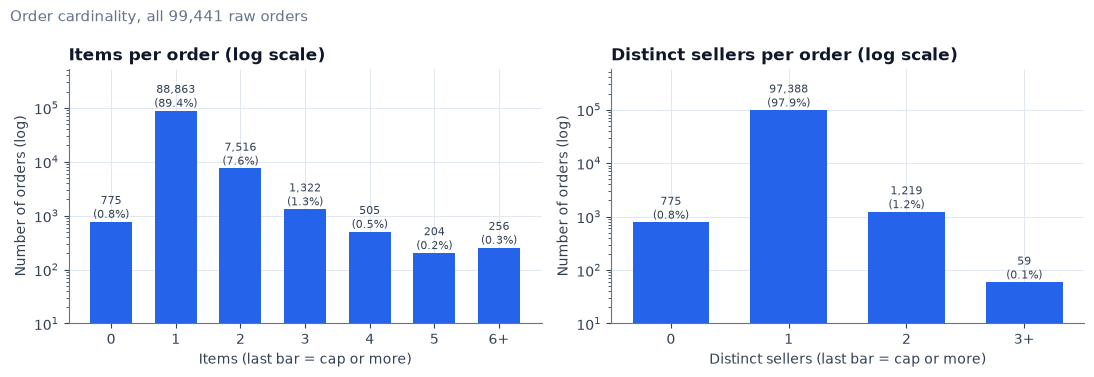

,value
orders,"99,441.0"
orders without any item row,775.0
orders with >= 2 items,"9,803.0"
orders with >= 2 distinct sellers,"1,278.0"
max items in one order,21.0
max sellers in one order,5.0
mean items per order (orders that have items),1.142


In [9]:
n_orders_total = orders.order_id.nunique()
per_order = items.groupby("order_id").agg(n_items=("order_item_id", "size"),
                                          n_sellers=("seller_id", "nunique"),
                                          n_products=("product_id", "nunique"))
per_order = per_order.reindex(orders.order_id).fillna(0).astype(int)   # orders without item rows -> 0

def capped_counts(s: pd.Series, cap: int) -> pd.Series:
    c = s.clip(upper=cap).value_counts().sort_index()
    c.index = [f"{i}+" if i == cap else str(i) for i in c.index]
    return c

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, cap, ttl in [(axes[0], "n_items", 6, "Items per order"),
                          (axes[1], "n_sellers", 3, "Distinct sellers per order")]:
    c = capped_counts(per_order[col], cap)
    bars = ax.bar(c.index, c.values, color=P["blue"], width=0.65)
    ax.set_yscale("log")
    ax.set_title(f"{ttl} (log scale)")
    ax.set_xlabel(ttl.split(" per")[0] + (" (last bar = cap or more)"))
    ax.set_ylabel("Number of orders (log)")
    for b, v in zip(bars, c.values):
        ax.annotate(f"{v:,}\n({v / n_orders_total:.1%})", (b.get_x() + b.get_width() / 2, v),
                    ha="center", va="bottom", fontsize=8, color=P["slate"])
    ax.set_ylim(10, c.max() * 6)
fig.suptitle(f"Order cardinality, all {n_orders_total:,} raw orders", x=0.01, ha="left",
             fontsize=11, color=P["slate_light"])
save_show(fig, "01_order_cardinality")

summary = pd.Series({
    "orders": n_orders_total,
    "orders without any item row": int((per_order.n_items == 0).sum()),
    "orders with >= 2 items": int((per_order.n_items >= 2).sum()),
    "orders with >= 2 distinct sellers": int((per_order.n_sellers >= 2).sum()),
    "max items in one order": int(per_order.n_items.max()),
    "max sellers in one order": int(per_order.n_sellers.max()),
    "mean items per order (orders that have items)": round(per_order.loc[per_order.n_items > 0, "n_items"].mean(), 3),
})
summary.map(lambda v: f"{v:,}" if float(v).is_integer() else f"{v:.3f}").to_frame("value")

**What we learn**

* All foreign keys are complete: there are **0 orphan rows** in every join, so inner/left joins never silently drop data. The only gap is
  13 product rows whose category is missing from the translation file (2 distinct categories, handled in section 2).
* `orders` is 1:N with `order_items` (112,650 item rows for 99,441 orders). **89.4%** of orders (88,863) have exactly one item, 7.6% have two;
  9,803 orders have two or more items. The maximum is 21 items in one order; mean = 1.142 items per order among orders that have items.
* **775 orders have no item rows at all** (0.8%). They are almost all `unavailable` or `canceled` (see the status table below), and can never carry a delivery outcome.
* **1,278 orders involve 2 or more distinct sellers** (the maximum is 5). Such an order has one customer-facing delivery promise
  but several shipments, so a single "the seller's state" is ill-defined. The project handles it by choosing a deterministic
  *representative seller* (section 3) and keeping `n_sellers` as a feature.
* `customer_id` is unique per order (max one order per `customer_id`); the 99,441 `customer_id` values map to 96,096 `customer_unique_id`
  values, so some people ordered more than once. `review_id` is **not** unique (98,410 distinct in 99,224 rows) and 547 orders have more than one review,
  which is why the pipeline keeps the latest review per order.

## 2. Data quality & cleaning decisions

For every issue below we (a) measure it, (b) state the decision, and (c) point at the code in `src/preprocessing.py` /
`src/feature_engineering.py` that implements it.

### 2.1 Missing values

,table,column,missing,rows,pct_missing
0,reviews,review_comment_title,87656,99224,88.342
1,reviews,review_comment_message,58247,99224,58.703
2,orders,order_delivered_customer_date,2965,99441,2.982
3,products,product_category_name,610,32951,1.851
4,products,product_name_lenght,610,32951,1.851
5,products,product_description_lenght,610,32951,1.851
6,products,product_photos_qty,610,32951,1.851
7,orders,order_delivered_carrier_date,1783,99441,1.793
8,orders,order_approved_at,160,99441,0.161
9,products,product_weight_g,2,32951,0.006


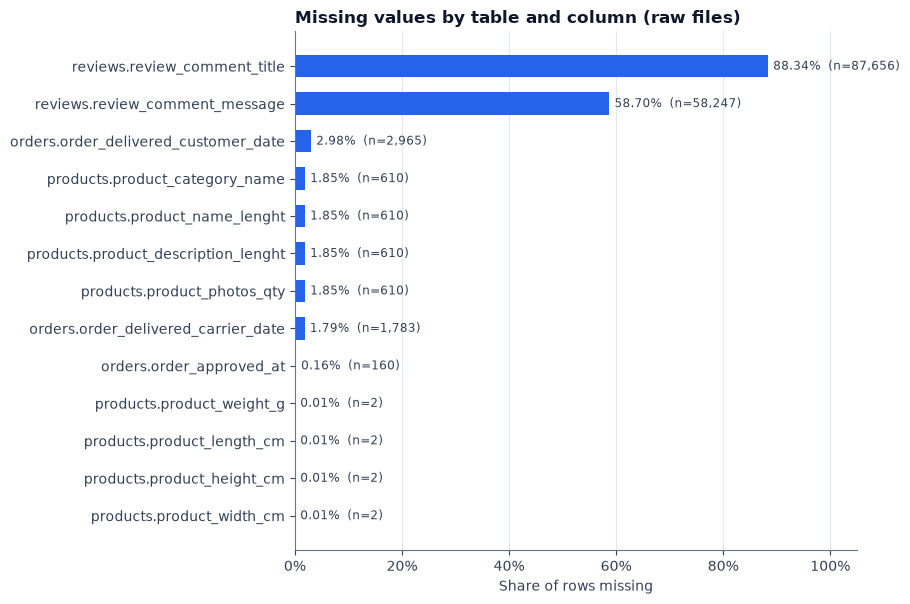

In [10]:
miss_rows = []
for name, t in tables.items():
    m = t.isna().sum()
    for col, k in m[m > 0].items():
        miss_rows.append({"table": name, "column": col, "missing": int(k), "rows": len(t), "pct_missing": 100 * k / len(t)})
missing = pd.DataFrame(miss_rows).sort_values("pct_missing", ascending=False).reset_index(drop=True)
display(missing)

lab = missing["table"] + "." + missing["column"]
fig, ax = plt.subplots(figsize=(9, 0.38 * len(missing) + 1.2))
ax.barh(lab[::-1], missing["pct_missing"][::-1], color=P["blue"], height=0.6)
for y, (pct, k) in enumerate(zip(missing["pct_missing"][::-1], missing["missing"][::-1])):
    ax.text(pct + 1, y, f"{pct:.2f}%  (n={k:,})", va="center", fontsize=8.5, color=P["slate"])
ax.set_xlim(0, 105); ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_xlabel("Share of rows missing"); ax.set_title("Missing values by table and column (raw files)")
ax.grid(axis="y", visible=False)
save_show(fig, "02_missing_values")

In [11]:
dup_rows = []
key_map = {"orders": ["order_id"], "items": ["order_id", "order_item_id"], "customers": ["customer_id"],
           "sellers": ["seller_id"], "products": ["product_id"], "reviews": ["review_id", "order_id"],
           "category_translation": ["product_category_name"]}
for name, t in tables.items():
    dup_rows.append({"table": name, "rows": len(t), "exact_duplicate_rows": int(t.duplicated().sum()),
                     "duplicate_keys": int(t.duplicated(key_map[name]).sum()), "key": ", ".join(key_map[name])})
dup_df = pd.DataFrame(dup_rows)
display(dup_df)
print("Reviews: repeated order_id =", int(reviews.order_id.duplicated().sum()),
      "| repeated review_id =", int(reviews.review_id.duplicated().sum()),
      "(a review_id can be attached to several orders; handled by keeping the latest review per order)")

,table,rows,exact_duplicate_rows,duplicate_keys,key
0,orders,99441,0,0,order_id
1,items,112650,0,0,"order_id, order_item_id"
2,customers,99441,0,0,customer_id
3,sellers,3095,0,0,seller_id
4,products,32951,0,0,product_id
5,reviews,99224,0,0,"review_id, order_id"
6,category_translation,71,0,0,product_category_name


Reviews: repeated order_id = 551 | repeated review_id = 814 (a review_id can be attached to several orders; handled by keeping the latest review per order)


In [12]:
ts_cols = config.TIMESTAMP_COLS
parse_rows = []
op = orders.copy()
for c in ts_cols:
    raw_missing = int(op[c].isna().sum())
    parsed = pd.to_datetime(op[c], format="%Y-%m-%d %H:%M:%S", errors="coerce")
    parse_rows.append({"column": c, "raw_missing": raw_missing,
                       "unparseable_non_missing": int(parsed.isna().sum() - raw_missing),
                       "earliest": parsed.min(), "latest": parsed.max()})
    op[c] = parsed
display(pd.DataFrame(parse_rows).set_index("column"))
print("Estimated-delivery timestamps all at midnight? ->",
      bool((op.order_estimated_delivery_date.dt.normalize() == op.order_estimated_delivery_date).all()))

,raw_missing,unparseable_non_missing,earliest,latest
column,,,,
order_purchase_timestamp,0,0,2016-09-04 21:15:19,2018-10-17 17:30:18
order_approved_at,160,0,2016-09-15 12:16:38,2018-09-03 17:40:06
order_delivered_carrier_date,1783,0,2016-10-08 10:34:01,2018-09-11 19:48:28
order_delivered_customer_date,2965,0,2016-10-11 13:46:32,2018-10-17 13:22:46
order_estimated_delivery_date,0,0,2016-09-30 00:00:00,2018-11-12 00:00:00


Estimated-delivery timestamps all at midnight? -> True


In [13]:
T = op
anoms = {
    "approved before purchase": T.order_approved_at < T.order_purchase_timestamp,
    "carrier pickup before purchase": T.order_delivered_carrier_date < T.order_purchase_timestamp,
    "carrier pickup before approval": T.order_delivered_carrier_date < T.order_approved_at,
    "customer delivery before carrier pickup": T.order_delivered_customer_date < T.order_delivered_carrier_date,
    "customer delivery before purchase": T.order_delivered_customer_date < T.order_purchase_timestamp,
    "estimate before purchase": T.order_estimated_delivery_date < T.order_purchase_timestamp,
}
delivered_mask = T.order_status == "delivered"
anom_df = pd.DataFrame({
    "all orders": {k: int(v.sum()) for k, v in anoms.items()},
    "delivered orders": {k: int((v & delivered_mask).sum()) for k, v in anoms.items()},
})
display(anom_df)

# the gap size for the two anomalies that the pipeline handles explicitly
gap = (T.order_purchase_timestamp - T.order_delivered_carrier_date).dt.total_seconds() / 3600
print("Carrier-before-purchase rows: how many hours EARLIER than the purchase the carrier timestamp is:")
print(gap[gap > 0].describe(percentiles=[.5, .9]).round(1).to_string())

,all orders,delivered orders
approved before purchase,0,0
carrier pickup before purchase,166,165
carrier pickup before approval,1359,1350
customer delivery before carrier pickup,23,23
customer delivery before purchase,0,0
estimate before purchase,0,0


Carrier-before-purchase rows: how many hours EARLIER than the purchase the carrier timestamp is:
count     166.000
mean       26.000
std       318.900
min         0.000
50%         0.600
90%         1.500
max     4,109.100


**Reading the checks**

* **Missing values:** the two review *comment* columns are mostly empty (88.34% and 58.70%) — people rarely write text, expected and irrelevant to delivery.
  What matters for this project: `order_delivered_customer_date` is missing for 2,965 orders (2.98%), `order_delivered_carrier_date` for 1,783 (1.79%), and
  `order_approved_at` for 160 (0.16%). 610 products (1.85%) lack category/name/description/photo count; 2 products lack weight and dimensions.
* **Duplicates:** there are **no exact duplicate rows** and **no duplicate primary keys** in any table. The only repeated keys are in reviews
  (a review ID shared by several orders; 551 repeated `order_id` rows), handled by keeping the latest review per order. The pipeline still checks and de-duplicates defensively.
* **Timestamps:** every non-missing timestamp parses with the format `%Y-%m-%d %H:%M:%S` (0 unparseable). The estimated delivery date always has time 00:00:00 — it is a *calendar date*, not a moment. This matters for the lateness definition (section 3).
* **Logical anomalies** (delivered orders in brackets): no order is approved before purchase, delivered before purchase, or has an estimate before purchase.
  But **166 carrier-pickup timestamps are earlier than the purchase** (165 delivered); the median is only 0.6 h earlier (90th percentile 1.5 h), so mostly clock/entry skew,
  yet a few are days or months early (max about 4,109 h). **1,359** carrier timestamps precede the approval timestamp (plausible when sellers ship before payment is approved), and **23** customer-delivery
  timestamps precede the carrier pickup.
* **Decisions:** the 166 carrier-before-purchase rows are *kept* (the order itself is fine) but flagged `carrier_date_invalid = 1` and their `processing_days` is set to NaN rather than "fixed"
  (`add_delivery_targets`). The 23 impossible carrier→customer gaps are set to NaN for `carrier_to_customer_days`. We do not use the carrier-before-approval pattern because it is not an error.
  None of these diagnostics is known at purchase time anyway, so they never feed a predictor.

### 2.2 Order status

,orders,share_pct,has_customer_delivery_date,has_item_rows
order_status,,,,
delivered,96478,97.020,96470,96478
shipped,1107,1.113,0,1106
canceled,625,0.629,6,461
unavailable,609,0.612,0,6
invoiced,314,0.316,0,312
processing,301,0.303,0,301
created,5,0.005,0,0
approved,2,0.002,0,2


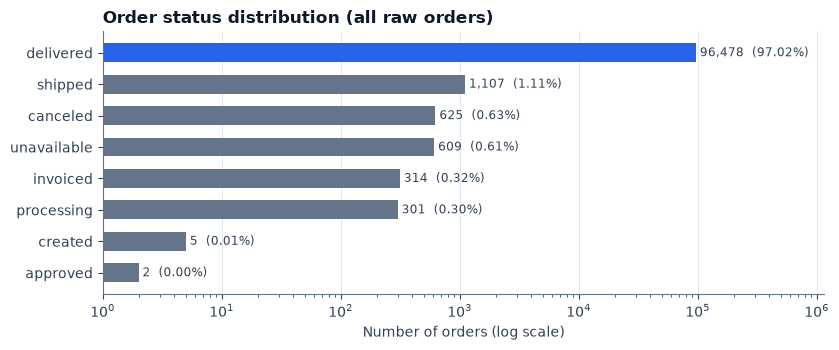

In [14]:
status = orders.order_status.value_counts()
st_df = pd.DataFrame({"orders": status, "share_pct": 100 * status / status.sum()})
st_df["has_customer_delivery_date"] = orders.dropna(subset=["order_delivered_customer_date"]).order_status.value_counts().reindex(st_df.index).fillna(0).astype(int)
st_df["has_item_rows"] = orders[orders.order_id.isin(items.order_id)].order_status.value_counts().reindex(st_df.index).fillna(0).astype(int)
display(st_df)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
s = status.sort_values()
ax.barh(s.index, s.values, color=[P["blue"] if i == "delivered" else P["slate_light"] for i in s.index], height=0.6)
ax.set_xscale("log")
for y, v in enumerate(s.values):
    ax.text(v * 1.08, y, f"{v:,}  ({v / status.sum():.2%})", va="center", fontsize=8.5, color=P["slate"])
ax.set_xlim(1, status.max() * 12)
ax.set_xlabel("Number of orders (log scale)"); ax.set_title("Order status distribution (all raw orders)")
ax.grid(axis="y", visible=False)
save_show(fig, "03_order_status")

**Why cancelled / undelivered orders are excluded**

The analysis set must contain orders for which we *observe* whether the promise was kept.

* **96,478 orders (97.02%) are `delivered`**; of those, **8 have no customer-delivery timestamp** and cannot be classified, leaving **96,470 eligible orders**.
* The other **2,963 orders** (`shipped` 1,107; `canceled` 625; `unavailable` 609; `invoiced` 314; `processing` 301; `created` 5; `approved` 2) have no delivery outcome:
  none of the shipped / unavailable / invoiced / processing orders has a customer-delivery date, and only 6 of the 625 cancelled orders has one.
* Treating these as "on time" would inflate on-time performance with orders that never arrived; treating them as "late" would be equally unfounded for orders still in transit. They get `is_late = <NA>`
  and an `exclusion_reason` (`status_<status>`), and are never counted as on time. 603 `unavailable` orders also have no item rows.
* **Consequence (selection bias):** all statistics in this project describe *delivered* orders only. Any problem that *prevents* delivery (cancellations, stock-outs) is invisible in the late rate.

### 2.3 Product-category missingness and zero weights

In [15]:
# --- product-category missingness and zero weights -------------------------------------
cat_missing_products = products.product_category_name.isna().sum()
items_p = items.merge(products, on="product_id", how="left")
items_cat_missing = items_p.product_category_name.isna().sum()
print(f"Products with no category            : {cat_missing_products:,} of {len(products):,} ({cat_missing_products/len(products):.2%})")
print(f"Item rows whose product has no category: {items_cat_missing:,} of {len(items):,} ({items_cat_missing/len(items):.2%})")
not_in_tr = sorted(set(products.product_category_name.dropna()) - set(translation.product_category_name))
print(f"Categories absent from the translation file ({len(not_in_tr)}): {not_in_tr}")

w = products.product_weight_g
print(f"\nProducts missing weight : {int(w.isna().sum())}   | with weight == 0 g : {int((w == 0).sum())}")
dims = ["product_length_cm", "product_height_cm", "product_width_cm"]
print("Products with a non-positive dimension:", int((products[dims] <= 0).any(axis=1).sum()))
print("Weight (g) quantiles:", products.product_weight_g.quantile([0, .01, .5, .99, 1]).round(0).to_dict())
display(products[products.product_weight_g == 0][["product_id", "product_category_name", "product_weight_g"]].assign(
    product_id=lambda d: d.product_id.str[:10] + "..."))

Products with no category            : 610 of 32,951 (1.85%)
Item rows whose product has no category: 1,603 of 112,650 (1.42%)
Categories absent from the translation file (2): ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']

Products missing weight : 2   | with weight == 0 g : 4
Products with a non-positive dimension: 0
Weight (g) quantiles: {0.0: 0.0, 0.01: 60.0, 0.5: 700.0, 0.99: 22538.0, 1.0: 40425.0}


,product_id,product_category_name,product_weight_g
9769,81781c0fed...,cama_mesa_banho,0.000
13683,8038040ee2...,cama_mesa_banho,0.000
14997,36ba42dd18...,cama_mesa_banho,0.000
32079,e673e90efa...,cama_mesa_banho,0.000


**Findings.** 610 products (1.85%) have no category, which affects 1,603 item rows (1.42%). In the analysis set, 1,358 orders end up with an *unknown* representative category (1.41%).
Two categories that do occur in `products` (`pc_gamer`, `portateis_cozinha_e_preparadores_de_alimentos`) are absent from the official translation file (13 product rows). Four products have a weight of exactly **0 g**
(all `cama_mesa_banho`, i.e. bed/bath/table, which cannot weigh 0 g) and two have missing weight and dimensions.

### 2.4 Cleaning decisions and where they are implemented

| Issue (measured above) | Decision | Implemented in |
|---|---|---|
| Cancelled / unavailable / shipped / in-progress orders; delivered with no delivery date | Kept in `orders_all` but `analysis_eligible = False`, `is_late = <NA>`, `exclusion_reason` set; never labelled on time | `feature_engineering.add_delivery_targets` |
| Estimated date has no time of day | Lateness is judged on **calendar dates** | `add_delivery_targets` (`delivery_delay_days`, `is_late`) |
| Carrier timestamp before purchase (166) | Row kept, `carrier_date_invalid = 1`, `processing_days = NaN` | `add_delivery_targets` |
| Customer delivery before carrier pickup (23) / negative approval gap | Gap set to NaN, never silently swapped | `add_delivery_targets` |
| Items with several rows / several sellers | Aggregated to one row per order with a deterministic representative seller & category | `feature_engineering.aggregate_items` |
| Missing category (610 products) | Category becomes `"unknown"`, `category_missing = 1` | `aggregate_items` |
| Category missing from translation (2) | Documented supplement mapping | `preprocessing.SUPPLEMENTAL_TRANSLATIONS` |
| Weight / dimension of 0 or missing (6 products) | Treated as missing (NaN) + `weight_missing = 1`; imputation (median, fit on training data only) is left to the model pipeline | `aggregate_items` |
| Multiple reviews for one order | Keep the latest per order; `review_score` is descriptive only | `preprocessing._reduce_reviews` |
| Duplicates | Exact duplicates dropped, repeated keys keep first (none found in orders / items) | `preprocessing._inspect_and_dedupe` |
| Customer / seller identifiers | Not carried into processed tables (privacy) | `feature_engineering.PROCESSED_COLUMNS`, `validate_processed` |

### 2.5 Reconciling this notebook with the real pipeline

Below we recompute the headline counts **independently** (plain pandas, own timestamp parsing, own lateness rule) and compare with
(1) the quality report written by the pipeline, and (2) a fresh call of `src.preprocessing.build_orders_table`. A disagreement would stop the notebook with an assertion error.

In [16]:
# --- independent recomputation vs the real pipeline ----------------------------------
raw = load_raw()                                  # the pipeline's own loader (all columns as str)
pipe_all, report = build_orders_table(raw)        # the pipeline's order-level table + quality report
proc = load_processed()                           # parquet written by `python -m src.preprocessing`

o = op                                            # parsed timestamps from the cells above
elig_nb = (o.order_status == "delivered") & o.order_delivered_customer_date.notna() \
          & o.order_estimated_delivery_date.notna() & o.order_purchase_timestamp.notna() \
          & (o.order_delivered_customer_date >= o.order_purchase_timestamp)
late_nb = (o.order_delivered_customer_date.dt.normalize() > o.order_estimated_delivery_date.dt.normalize())[elig_nb]
late_ts_nb = (o.order_delivered_customer_date > o.order_estimated_delivery_date)[elig_nb]

cmp = pd.DataFrame([
    ("raw orders", len(orders), report["n_orders_raw"], len(pipe_all)),
    ("status = delivered", int((orders.order_status == "delivered").sum()), report["order_status_counts"]["delivered"],
     int((pipe_all.order_status == "delivered").sum())),
    ("eligible (analysis set)", int(elig_nb.sum()), report["n_eligible"], int(pipe_all.analysis_eligible.sum())),
    ("late orders (calendar-date rule)", int(late_nb.sum()), report["n_late_eligible"], int(pipe_all.is_late.fillna(0).sum())),
    ("late rate (calendar-date)", round(float(late_nb.mean()), 6), round(report["late_rate_eligible"], 6),
     round(float(pipe_all.is_late.dropna().mean()), 6)),
    ("late rate (timestamp-based, reference)", round(float(late_ts_nb.mean()), 6),
     round(report["late_rate_timestamp_based_for_reference"], 6), np.nan),
    ("multi-seller orders", int((per_order.n_sellers > 1).sum()), report["multi_seller_orders"],
     int((pipe_all.n_sellers > 1).sum())),
    ("carrier-before-purchase (all orders)", int(anoms["carrier pickup before purchase"].sum()),
     report["logical_order_anomalies_all_orders"]["carrier_before_purchase"], int(pipe_all.carrier_date_invalid.sum())),
], columns=["metric", "notebook (independent)", "pipeline report (JSON)", "pipeline table (re-run now)"])
cmp["agree"] = [
    bool(np.isclose(a, b) and (np.isnan(c) or np.isclose(a, c)))
    for a, b, c in zip(cmp.iloc[:, 1], cmp.iloc[:, 2], cmp.iloc[:, 3].astype(float))
]
fmt = lambda v: "" if pd.isna(v) else (f"{v:,.0f}" if float(v).is_integer() else f"{v:.4f}")
display(cmp.assign(**{c: cmp[c].map(fmt) for c in cmp.columns[1:4]}))
assert cmp["agree"].all(), "notebook and pipeline disagree"

print("Saved parquet matches a fresh pipeline run:",
      len(proc) == int(pipe_all.analysis_eligible.sum()) and set(proc.order_id) == set(pipe_all.loc[pipe_all.analysis_eligible, "order_id"]))
print("Validation problems reported by the pipeline:", report["validation_problems"] or "none")
print("Exclusions:", report["exclusions"])

,metric,notebook (independent),pipeline report (JSON),pipeline table (re-run now),agree
0,raw orders,"99,441","99,441","99,441",True
1,status = delivered,"96,478","96,478","96,478",True
2,eligible (analysis set),"96,470","96,470","96,470",True
3,late orders (calendar-date rule),"6,534","6,534","6,534",True
4,late rate (calendar-date),0.0677,0.0677,0.0677,True
5,"late rate (timestamp-based, reference)",0.0811,0.0811,,True
6,multi-seller orders,"1,278","1,278","1,278",True
7,carrier-before-purchase (all orders),166,166,166,True


Saved parquet matches a fresh pipeline run: True
Validation problems reported by the pipeline: none
Exclusions: {'non_delivered_status': 2963, 'delivered_missing_delivery_date': 8, 'delivered_before_purchase': 0, 'delivered_no_items': 0, 'missing_purchase_or_estimate': 0}


**Result:** all eight headline metrics agree across the three sources — 99,441 raw orders, 96,478 delivered, **96,470 eligible**, **6,534 late orders**, a calendar-date late rate of **6.77%**
(timestamp-based reference 8.11%, discussed next), 1,278 multi-seller orders and 166 carrier-before-purchase rows. The parquet file on disk also matches a fresh pipeline run, and the pipeline's own
`validate_processed` reports no problems. From here on we use the processed analysis set (`data/processed/orders_delivered.parquet`).

## 3. Feature-engineering walk-through on real orders

The analysis set has one row per eligible order. Three real orders are shown first; each engineered value is then **re-derived by hand** from raw timestamps and asserted equal to the pipeline output.

* `delivery_duration_days` = delivery timestamp − purchase timestamp, in fractional days.
* `estimated_delivery_days` = estimated date − purchase date (both at midnight, whole days) — the promise visible at checkout, so *known at purchase time*.
* `delivery_delay_days` = delivery **calendar date** − estimated **calendar date** (negative = early).
* `is_late` = 1 if `delivery_delay_days > 0`, else 0.
* `processing_days` = carrier-pickup timestamp − purchase timestamp (**RETROSPECTIVE**; NaN if the pickup is missing or before purchase).

The examples: the eligible order whose duration is closest to the on-time median, the late order whose delay is closest to the late-order median, and a *boundary case* delivered on the estimated date itself.

In [17]:
d = proc.copy()
# processed categorical columns are pandas 'category' dtype -> use observed=True in groupbys
for c in d.select_dtypes("category").columns:
    d[c] = d[c].cat.remove_unused_categories()
N = len(d)
BASE_LATE = d.is_late.astype(int).mean()
print(f"Analysis set: {N:,} orders | late = {int(d.is_late.sum()):,} ({BASE_LATE:.2%}) | "
      f"purchases {d.order_purchase_timestamp.min():%Y-%m-%d} .. {d.order_purchase_timestamp.max():%Y-%m-%d}")

show_cols = ["order_purchase_timestamp", "order_delivered_carrier_date", "order_delivered_customer_date",
             "order_estimated_delivery_date", "delivery_duration_days", "estimated_delivery_days",
             "delivery_delay_days", "is_late", "processing_days"]

# Example 1: a typical early delivery (the order closest to the median duration among on-time orders)
on_time = d[d.is_late == 0]
ex_ontime = on_time.iloc[(on_time.delivery_duration_days - on_time.delivery_duration_days.median()).abs().argsort()[:1]]
# Example 2: a late order closest to the median delay among late orders
late = d[d.is_late == 1]
ex_late = late.iloc[(late.delivery_delay_days - late.delivery_delay_days.median()).abs().argsort()[:1]]
# Example 3: boundary -- delivered ON the estimated calendar date but after midnight
same_day = d[(d.order_delivered_customer_date.dt.normalize() == d.order_estimated_delivery_date)
             & (d.order_delivered_customer_date > d.order_estimated_delivery_date)]
ex_boundary = same_day.sort_values("order_id").iloc[:1]
print(f"Orders delivered on the estimated calendar date (after 00:00): {len(same_day):,} "
      f"-> all labelled is_late = {sorted(same_day.is_late.unique().tolist())}")

ex = pd.concat([ex_ontime.assign(example="typical on-time"), ex_late.assign(example="typical late"),
                ex_boundary.assign(example="boundary: delivered on the estimate date")])
ex["order_id"] = ex.order_id.str[:8] + "..."
ex.set_index("example")[["order_id"] + show_cols].T

Analysis set: 96,470 orders | late = 6,534 (6.77%) | purchases 2016-09-15 .. 2018-08-29
Orders delivered on the estimated calendar date (after 00:00): 1,292 -> all labelled is_late = [0]


example,typical on-time,typical late,boundary: delivered on the estimate date
order_id,386ea83c...,2c6909e9...,0005a1a1...
order_purchase_timestamp,2017-09-15 22:08:17,2017-09-15 13:26:45,2018-03-19 18:40:33
order_delivered_carrier_date,2017-09-19 20:07:44,2017-09-22 20:37:08,2018-03-28 00:37:42
order_delivered_customer_date,2017-09-25 17:37:05,2017-10-18 23:19:55,2018-03-29 18:17:31
order_estimated_delivery_date,2017-10-03 00:00:00,2017-10-11 00:00:00,2018-03-29 00:00:00
delivery_duration_days,9.812,33.412,9.984
estimated_delivery_days,18,26,10
delivery_delay_days,-8,7,0
is_late,0,1,0
processing_days,3.916,7.299,8.248


In [18]:
# Re-derive each engineered column by hand from the raw timestamps and compare with the pipeline output.
r = d[d.order_id.isin(pd.concat([ex_ontime, ex_late, ex_boundary]).order_id)].copy()
manual = pd.DataFrame({
    "duration_days": (r.order_delivered_customer_date - r.order_purchase_timestamp).dt.total_seconds() / 86400,
    "delay_days": (r.order_delivered_customer_date.dt.normalize() - r.order_estimated_delivery_date.dt.normalize()).dt.days,
    "promise_days": (r.order_estimated_delivery_date.dt.normalize() - r.order_purchase_timestamp.dt.normalize()).dt.days,
    "processing_days": (r.order_delivered_carrier_date - r.order_purchase_timestamp).dt.total_seconds() / 86400,
})
manual["is_late (rule: delay > 0)"] = (manual.delay_days > 0).astype(int)
manual["timestamp-based late (deliv > estimate)"] = (r.order_delivered_customer_date > r.order_estimated_delivery_date).astype(int)
manual["pipeline is_late"] = r.is_late.astype(int)
manual.index = r.order_id.str[:8] + "..."
display(manual)
assert np.allclose(manual.duration_days, r.delivery_duration_days.values)
assert (manual.delay_days.values == r.delivery_delay_days.astype(int).values).all()
assert (manual.promise_days.values == r.estimated_delivery_days.astype(int).values).all()
assert np.allclose(manual.processing_days, r.processing_days.values)
assert (manual["is_late (rule: delay > 0)"].values == manual["pipeline is_late"].values).all()
print("Manual derivations match the pipeline columns for the example orders.")

,duration_days,delay_days,promise_days,processing_days,is_late (rule: delay > 0),timestamp-based late (deliv > estimate),pipeline is_late
order_id,,,,,,,
2c6909e9...,33.412,7,26,7.299,1,1,1
386ea83c...,9.812,-8,18,3.916,0,0,0
0005a1a1...,9.984,0,10,8.248,0,1,0


Manual derivations match the pipeline columns for the example orders.


**Reading the examples.** The typical on-time order was delivered 8 days before the estimated date (delay = −8); the typical late order arrived 7 days after the promise
(delay = +7, a 33.4-day journey against a 26-day promise).

**The boundary case (`0005a1a1...`)** is delivered on 2018-03-29 at 18:17:31, and the estimated date is 2018-03-29. The estimate is stored as `00:00:00`, but a customer promised delivery "by 29 March" is not late
at 18:17 on 29 March. A strict timestamp comparison would call it late (the last extra column in the table above shows 1), the calendar rule correctly gives `delay = 0`, `is_late = 0`.

### Calendar-date vs timestamp lateness

In [19]:
# Late-rate definition comparison on the full analysis set
cal_late = d.is_late.astype(int)
ts_late = (d.order_delivered_customer_date > d.order_estimated_delivery_date).astype(int)
cmp_def = pd.DataFrame({
    "definition": ["calendar date: delivery date > estimated date  (used in this project)",
                   "timestamp: delivery time > estimated midnight  (reference only)"],
    "late_orders": [int(cal_late.sum()), int(ts_late.sum())],
    "n": [N, N],
    "late_rate_pct": [100 * cal_late.mean(), 100 * ts_late.mean()],
})
display(cmp_def)
diff = int(((ts_late == 1) & (cal_late == 0)).sum())
print(f"Orders late by timestamp but on time by calendar date: {diff:,} ({diff / N:.2%} of all orders)")
print("...of which delivered on the estimated calendar date itself:",
      int(((ts_late == 1) & (cal_late == 0) & (d.delivery_delay_days == 0)).sum()))
print("Share of eligible orders by delivery_delay_days == 0 :", f"{(d.delivery_delay_days == 0).mean():.2%}")

,definition,late_orders,n,late_rate_pct
0,calendar date: delivery date > estimated date ...,6534,96470,6.773
1,timestamp: delivery time > estimated midnight ...,7826,96470,8.112


Orders late by timestamp but on time by calendar date: 1,292 (1.34% of all orders)
...of which delivered on the estimated calendar date itself: 1292
Share of eligible orders by delivery_delay_days == 0 : 1.34%


**Why the two definitions differ.** The delivery promise carries only a *date*. Comparing a full delivery timestamp with midnight at the start of the promised day counts every delivery that happens on the promised day (after 00:00) as late. This affects
**1,292 orders (1.34% of all analysis orders)**, exactly the orders with `delivery_delay_days == 0`. The timestamp rule therefore reports 7,826 late orders (**8.11%**) against **6,534 (6.77%)** with the calendar rule used throughout this project, and the
difference of 1,292 orders is entirely made up of on-the-promised-day deliveries. The calendar rule matches what the promise means to the customer.

### Multi-seller example: how an order becomes one row

Raw `order_items` rows must be turned into a single order row. For orders with several sellers the project picks a **representative seller** (largest summed item price; ties → smallest `seller_id`) and a
**representative category** (category of the highest-priced item; ties → smallest `order_item_id`). `n_sellers`, `n_categories` and `n_items` retain the multi-seller information. The first example
(sorted by `order_id`) with exactly two sellers in different states and two different categories:

In [20]:
# Multi-seller example: pick the first (sorted by order_id) eligible order with 2 sellers in DIFFERENT states
# whose seller states differ from each other -- so the representative-seller rule visibly matters.
ms_ids = d.loc[d.n_sellers >= 2, "order_id"]
it = items[items.order_id.isin(ms_ids)].merge(sellers, on="seller_id").merge(
    products[["product_id", "product_category_name", "product_weight_g"]], on="product_id", how="left")
it = it.merge(translation, on="product_category_name", how="left")
per = it.groupby("order_id").agg(n_states=("seller_state", "nunique"), n_cats=("product_category_name_english", "nunique"),
                                 n_sellers=("seller_id", "nunique"))
cand = per[(per.n_states >= 2) & (per.n_cats >= 2) & (per.n_sellers == 2)].index.min()
ex_ms = it[it.order_id == cand].sort_values("order_item_id")
print(f"Multi-seller order {cand[:8]}... raw item rows (joined with sellers / products / translation):")
display(ex_ms[["order_item_id", "seller_id", "seller_state", "product_category_name_english", "price",
               "freight_value", "product_weight_g"]].assign(seller_id=lambda x: x.seller_id.str[:8] + "..."))

row = d[d.order_id == cand].iloc[0]
seller_sum = ex_ms.groupby(["seller_id", "seller_state"])["price"].sum().sort_values(ascending=False)
print("\nSummed price per seller (rule: largest total wins; ties -> smallest seller_id):")
print(seller_sum.round(2).to_string())
top_item = ex_ms.sort_values(["price", "order_item_id"], ascending=[False, True]).iloc[0]
print(f"\nHighest-priced item -> representative category rule gives: {top_item.product_category_name_english}")
print("\nEngineered order-level row:")
display(row[["n_items", "n_sellers", "n_categories", "seller_state", "customer_state", "same_state", "state_pair",
             "product_category", "total_price", "total_freight", "freight_ratio", "total_weight_g",
             "total_volume_cm3", "estimated_delivery_days", "delivery_duration_days", "is_late"]].to_frame(name="value").T)
assert row.seller_state == seller_sum.index[0][1]
assert row.product_category == top_item.product_category_name_english
assert np.isclose(row.total_price, ex_ms.price.sum()) and np.isclose(row.total_freight, ex_ms.freight_value.sum())
print("Representative seller state / category, total price and freight all re-derived correctly.")

Multi-seller order 002f98c0... raw item rows (joined with sellers / products / translation):


,order_item_id,seller_id,seller_state,product_category_name_english,price,freight_value,product_weight_g
0,1,7299e27e...,MG,consoles_games,8.990,32.570,450.000
1,2,fa40cc5b...,SP,toys,44.900,7.160,200.000



Summed price per seller (rule: largest total wins; ties -> smallest seller_id):
seller_id                         seller_state
fa40cc5b934574b62717c68f3d678b6d  SP             44.900
7299e27ed73d2ad986de7f7c77d919fa  MG              8.990

Highest-priced item -> representative category rule gives: toys

Engineered order-level row:


,n_items,n_sellers,n_categories,seller_state,customer_state,same_state,state_pair,product_category,total_price,total_freight,freight_ratio,total_weight_g,total_volume_cm3,estimated_delivery_days,delivery_duration_days,is_late
value,2,2,2,SP,RS,0,SP→RS,toys,53.890,39.730,0.737,650.000,"6,482.000",32,3.409,0


Representative seller state / category, total price and freight all re-derived correctly.


In [21]:
# Aggregates and geography on the whole analysis set
agg_view = d[["n_items", "n_sellers", "total_price", "total_freight", "freight_ratio", "total_weight_g",
              "total_volume_cm3", "estimated_delivery_days", "processing_days"]].describe(percentiles=[.5, .95]).T
agg_view["missing"] = d[agg_view.index].isna().sum()
display(agg_view)
print(f"same_state = 1 (representative seller and customer in the same state): {d.same_state.mean():.2%} of orders")
print(f"multi-item orders: {(d.n_items > 1).mean():.2%} | multi-seller orders: {(d.n_sellers > 1).mean():.2%}")

,count,mean,std,min,50%,95%,max,missing
n_items,"96,470.000",1.142,0.539,1.000,1.000,2.000,21.000,0
n_sellers,"96,470.000",1.014,0.124,1.000,1.000,1.000,5.000,0
total_price,"96,470.000",137.040,209.053,0.850,86.500,399.000,"13,440.000",0
total_freight,"96,470.000",22.786,21.560,0.000,17.170,54.780,"1,794.960",0
freight_ratio,"96,470.000",0.308,0.312,0.000,0.224,0.839,21.447,0
total_weight_g,"96,448.000","2,387.017","4,770.221",2.000,750.000,"10,500.000","184,400.000",22
total_volume_cm3,"96,454.000","17,331.937","30,143.871",168.000,"7,254.000","64,000.000","1,476,000.000",16
estimated_delivery_days,"96,470.000",24.373,8.758,3.000,24.000,39.000,156.000,0
processing_days,"96,304.000",3.235,3.554,0.000,2.205,8.877,125.776,166


same_state = 1 (representative seller and customer in the same state): 35.97% of orders
multi-item orders: 9.99% | multi-seller orders: 1.32%


**Reading the multi-seller order (`002f98c0...`).** It has two items from two sellers (MG and SP). The SP seller's item is the more expensive (BRL 44.90 vs 8.99), so the representative seller state is SP
and the representative category is `toys`; the customer is in RS, so `same_state = 0` and `state_pair = SP→RS`. Total price and freight are the item sums (BRL 53.89 and 39.73, `freight_ratio` = 0.737: freight is 74% of the goods value),
weight is 650 g, volume 6,482 cm³, the checkout promise was 32 days, and the actual duration 3.4 days (`is_late = 0`). All values were re-derived from the raw item rows in the cell above. Only 1.32% of analysis orders are multi-seller, so
this simplification affects few orders.

**Aggregates over the whole analysis set (table above):** median order value BRL 86.50 (mean 137.04, maximum 13,440), median freight BRL 17.17, median weight 750 g, median promise 24 days (mean 24.4), 35.97% of orders are
same-state, 9.99% are multi-item. Price, freight and weight are strongly right-skewed (skewness well above 1, see the summary table in section 4.9), which matters for modelling.

## 4. Exploratory analysis

All charts below are also saved as PNGs in `reports/figures/`. Unless stated otherwise the data is the analysis set (n = 96,470 delivered orders). Rates are shown with 95% Wilson confidence intervals where useful.

### 4.1 Target distribution and class imbalance

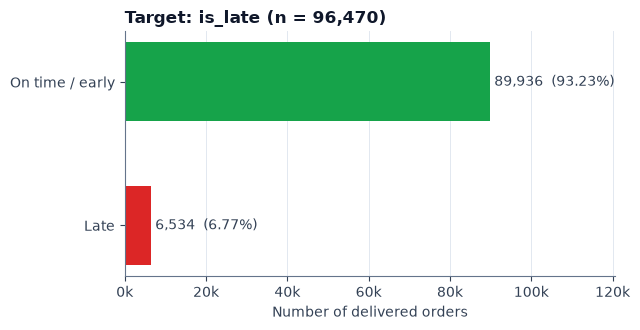

Class imbalance: 13.8 on-time orders per late order. A model that always predicts 'on time' would score 93.23% accuracy -> accuracy is a poor metric here.


In [22]:
tgt = d.is_late.map({0: "On time / early", 1: "Late"}).value_counts().reindex(["On time / early", "Late"])
fig, ax = plt.subplots(figsize=(6.5, 3.4))
bars = ax.barh(tgt.index[::-1], tgt.values[::-1], color=[P["red"], P["green"]], height=0.55)
for b, v in zip(bars, tgt.values[::-1]):
    ax.text(v + N * 0.01, b.get_y() + b.get_height() / 2, f"{v:,}  ({v / N:.2%})", va="center", color=P["slate"])
ax.set_xlim(0, N * 1.25); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax.set_xlabel("Number of delivered orders"); ax.set_title(f"Target: is_late (n = {N:,})")
ax.grid(axis="y", visible=False)
save_show(fig, "04_target_distribution")
print(f"Class imbalance: {tgt['On time / early'] / tgt['Late']:.1f} on-time orders per late order. "
      f"A model that always predicts 'on time' would score {1 - BASE_LATE:.2%} accuracy -> accuracy is a poor metric here.")

**Interpretation.** 6,534 orders (**6.77%**) were late and 89,936 (93.23%) on time or early: about **13.8 on-time orders per late order**. The classes are strongly imbalanced, so a trivial model that always answers
"on time" would be 93.23% accurate while detecting no late order. For the prediction work later, accuracy is the wrong headline metric; precision, recall, PR-AUC and calibrated probabilities are more informative.

### 4.2 Delivery duration and delay relative to the promise

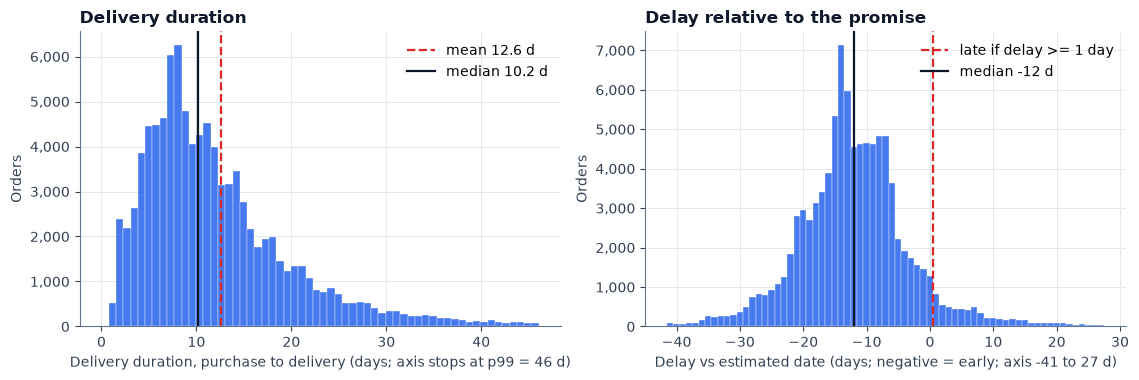

Orders beyond the plotted duration range: 965; beyond the delay range: 898
Duration quantiles (days): {'p50': 10.2, 'p90': 23.1, 'p95': 29.3, 'p99': 46.1} | skew = 3.83
Delay: median -12 d, mean -11.88 d | early (<0): 91.9% | on the date (=0): 1.3% | late (>0): 6.8%
Among the 6,534 late orders: median delay 7 d, mean 10.6 d, p90 22 d, max 188 d
Estimated promise (checkout): mean 24.4 d vs actual mean duration 12.6 d


In [23]:
dur = d.delivery_duration_days
q = dur.quantile([.5, .9, .95, .99])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
hi = dur.quantile(.99)
axes[0].hist(dur, bins=60, range=(0, hi), color=P["blue"], alpha=.85, edgecolor="white", linewidth=.3)
axes[0].axvline(dur.mean(), color=P["red"], lw=1.6, ls="--", label=f"mean {dur.mean():.1f} d")
axes[0].axvline(dur.median(), color=P["navy"], lw=1.6, label=f"median {dur.median():.1f} d")
axes[0].set_xlabel(f"Delivery duration, purchase to delivery (days; axis stops at p99 = {hi:.0f} d)")
axes[0].set_ylabel("Orders"); axes[0].set_title("Delivery duration"); axes[0].legend()
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

delay = d.delivery_delay_days.astype(int)
lo, hi2 = int(delay.quantile(.005)), int(delay.quantile(.995))
axes[1].hist(delay, bins=np.arange(lo - .5, hi2 + 1.5, 1), color=P["blue"], alpha=.85, edgecolor="white", linewidth=.3)
axes[1].axvline(0.5, color=P["red"], lw=1.6, ls="--", label="late if delay >= 1 day")
axes[1].axvline(delay.median(), color=P["navy"], lw=1.6, label=f"median {delay.median():.0f} d")
axes[1].set_xlabel(f"Delay vs estimated date (days; negative = early; axis {lo} to {hi2} d)")
axes[1].set_ylabel("Orders"); axes[1].set_title("Delay relative to the promise"); axes[1].legend()
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
save_show(fig, "05_duration_and_delay_distribution")

print(f"Orders beyond the plotted duration range: {(dur > hi).sum():,}; beyond the delay range: {((delay < lo) | (delay > hi2)).sum():,}")
print("Duration quantiles (days):", {f"p{int(k*100)}": round(v, 1) for k, v in q.items()}, "| skew =", round(dur.skew(), 2))
print(f"Delay: median {delay.median():.0f} d, mean {delay.mean():.2f} d | early (<0): {(delay < 0).mean():.1%} | "
      f"on the date (=0): {(delay == 0).mean():.1%} | late (>0): {(delay > 0).mean():.1%}")
L = d[d.is_late == 1].delivery_delay_days.astype(int)
print(f"Among the {len(L):,} late orders: median delay {L.median():.0f} d, mean {L.mean():.1f} d, p90 {L.quantile(.9):.0f} d, max {L.max()} d")
print(f"Estimated promise (checkout): mean {d.estimated_delivery_days.mean():.1f} d vs actual mean duration {dur.mean():.1f} d")

**Interpretation.**

* **Duration** is right-skewed: mean **12.6 days** vs median **10.2 days**, 90th percentile 23.1, 95th 29.3, 99th 46.1, skewness 3.83, maximum 209.6 days. The mean is pulled up by a long tail, so the median is the better "typical" value.
* **Delay vs promise:** the median order arrives **12 days before** the estimated date (mean −11.9 days). **91.9%** of orders are early, 1.3% arrive on the promised date and 6.8% late. The average checkout promise (24.4 days) is about twice the average
  actual duration (12.6 days). In other words, the promise is generous on average and "late" is a *tail event relative to a padded promise*, which is why lateness is much harder to predict than raw duration.
* **Late orders:** among the 6,534 late orders the median lateness is 7 days, mean 10.6, 90th percentile 22 days, maximum 188 days.

### 4.3 Monthly volume and late rate

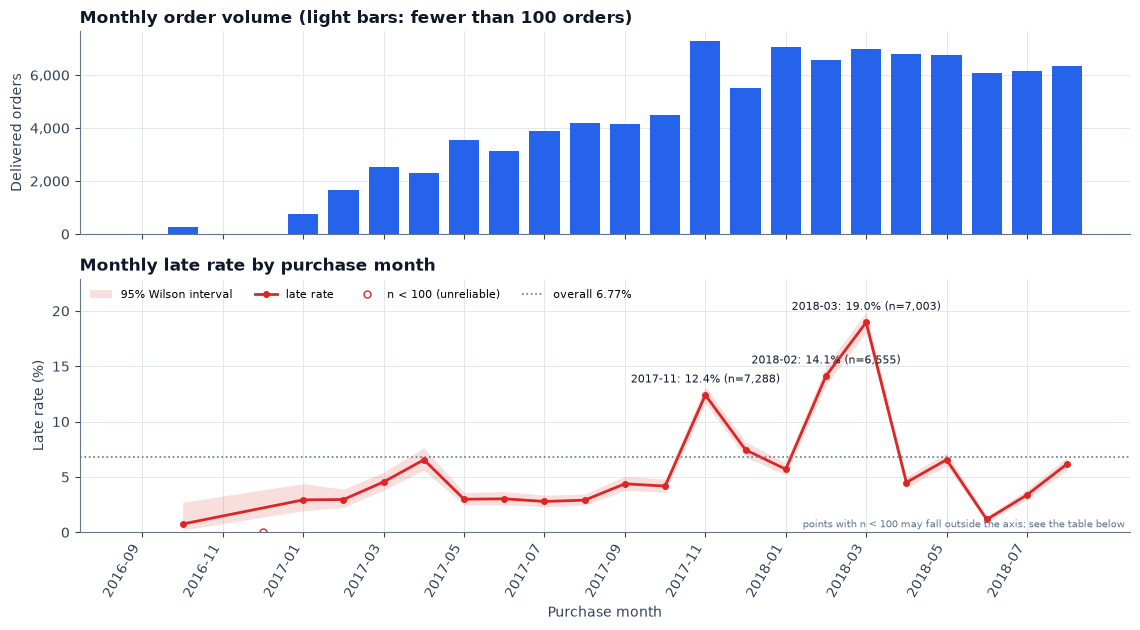

purchase_year_month,2016-09,2016-10,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
n,1,265,1,750,1653,2546,2303,3545,3135,3872,4193,4150,4478,7288,5513,7069,6555,7003,6798,6749,6096,6156,6351
late,1,2,0,22,49,116,151,106,95,108,122,182,187,904,411,403,926,1328,306,443,71,208,393
late_rate_pct,100.000,0.755,0.000,2.933,2.964,4.556,6.557,2.990,3.030,2.789,2.910,4.386,4.176,12.404,7.455,5.701,14.127,18.963,4.501,6.564,1.165,3.379,6.188
mean_dur,54.813,19.601,4.693,12.647,13.169,12.951,14.918,11.322,12.012,11.593,11.147,11.851,11.857,15.161,15.395,14.081,16.945,16.301,11.499,11.419,9.239,8.959,7.733


Months with n < 100: ['2016-09', '2016-12']
2016 eligible orders: 267
First month with n >= 100: 2016-10 | first month with n >= 500: 2017-01
Lowest 3 months by late rate (n >= 100):


,purchase_year_month,n,late,late_rate
0,2016-10,265,2,0.750
1,2018-06,6096,71,1.160
2,2017-07,3872,108,2.790


Top 5 months by late rate (n >= 100):


,purchase_year_month,n,late,late_rate
0,2018-03,7003,1328,18.960
1,2018-02,6555,926,14.130
2,2017-11,7288,904,12.400
3,2017-12,5513,411,7.460
4,2018-05,6749,443,6.560


In [24]:
mon = d.groupby("purchase_year_month", observed=True).agg(n=("is_late", "size"), late=("is_late", "sum"),
                                                        mean_dur=("delivery_duration_days", "mean")).reset_index()
mon["late_rate"] = mon.late / mon.n
mon["lo"], mon["hi"] = wilson(mon.late, mon.n)
mon["reliable"] = mon.n >= MIN_N
# Plot on a uniform calendar axis: months with no eligible orders stay as empty slots
full = pd.period_range(mon.purchase_year_month.min(), mon.purchase_year_month.max(), freq="M").astype(str)
pm = mon.assign(purchase_year_month=mon.purchase_year_month.astype(str)).set_index("purchase_year_month").reindex(full)
pm["n"] = pm.n.fillna(0)
pm["reliable"] = pm.reliable.fillna(False).astype(bool)
pm.index.name = "purchase_year_month"
x = np.arange(len(pm))
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11.5, 6.4), sharex=True, gridspec_kw={"height_ratios": [1, 1.25]})
a1.bar(x, pm.n, color=np.where(pm.reliable, P["blue"], P["blue_light"]), width=.75)
a1.set_ylabel("Delivered orders"); a1.set_title("Monthly order volume (light bars: fewer than %d orders)" % MIN_N)
a1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ok = pm.reliable.values
a2.fill_between(x[ok], (pm.lo * 100)[ok], (pm.hi * 100)[ok], color=P["red"], alpha=.15, lw=0, label="95% Wilson interval")
a2.plot(x[ok], (pm.late_rate * 100)[ok], color=P["red"], lw=2, marker="o", ms=4, label="late rate")
a2.plot(x[~ok], (pm.late_rate * 100)[~ok], ls="none", marker="o", ms=5, mfc="white", mec=P["red"], label=f"n < {MIN_N} (unreliable)")
a2.axhline(BASE_LATE * 100, color=P["slate_light"], ls=":", lw=1.2, label=f"overall {BASE_LATE:.2%}")
top = pm[pm.reliable].nlargest(3, "late_rate")
for lab_, rr in top.iterrows():
    a2.annotate(f"{lab_}: {rr.late_rate:.1%} (n={int(rr.n):,})", (full.get_loc(lab_), rr.late_rate * 100),
                xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8, color=P["navy"])
a2.set_ylabel("Late rate (%)"); a2.set_title("Monthly late rate by purchase month")
a2.set_xticks(x[::2]); a2.set_xticklabels(full[::2], rotation=60, ha="right")
a2.set_xlabel("Purchase month"); a2.legend(ncol=4, loc="upper left", fontsize=8)
a2.set_ylim(0, max(pm.hi[ok].max() * 100 * 1.15, 1))
a2.text(0.995, 0.02, "points with n < %d may fall outside the axis; see the table below" % MIN_N, transform=a2.transAxes, ha="right", fontsize=7.5, color=P["slate_light"])
save_show(fig, "06_monthly_volume_late_rate")

mt = mon.assign(late_rate_pct=100 * mon.late_rate)[["purchase_year_month", "n", "late", "late_rate_pct", "mean_dur"]]
display(mt.set_index("purchase_year_month").T.round(2))
print("Months with n < %d:" % MIN_N, mon.loc[~mon.reliable, "purchase_year_month"].tolist())
print("2016 eligible orders:", int((d.purchase_year == 2016).sum()))
print("First month with n >= %d:" % MIN_N, mon.loc[mon.reliable, "purchase_year_month"].iloc[0],
      "| first month with n >= 500:", mon.loc[mon.n >= 500, "purchase_year_month"].iloc[0])
print("Lowest 3 months by late rate (n >= %d):" % MIN_N)
display(mon[mon.reliable].nsmallest(3, "late_rate")[["purchase_year_month", "n", "late", "late_rate"]].assign(
    late_rate=lambda t: (100 * t.late_rate).round(2)).reset_index(drop=True))
print("Top 5 months by late rate (n >= %d):" % MIN_N)
display(mon[mon.reliable].nlargest(5, "late_rate")[["purchase_year_month", "n", "late", "late_rate"]].assign(
    late_rate=lambda t: (100 * t.late_rate).round(2)).reset_index(drop=True))

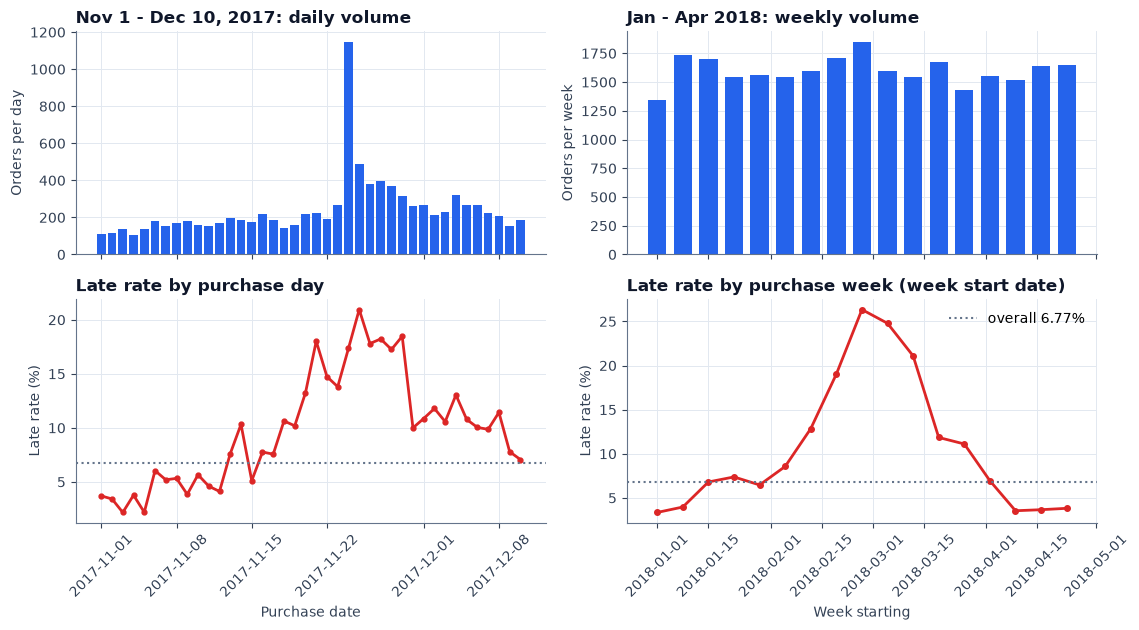

Busiest day in the window: 2017-11-24 with 1,147 orders (median of other days in window: 190); late rate that day 17.3%
Nov-2017 late rate for purchases up to Nov 19: 6.0% (n=3,033) | Nov 21-30: 17.2% (n=4,036)
Worst week Jan-Apr 2018: starting 2018-02-26, late rate 26.3% (n=1,849); mean checkout promise that week 22.9 d vs 24.4 d overall

Share of all purchased orders that are in the analysis set, last 9 purchase months:


ym,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10
orders,"6,728.000","7,211.000","6,939.000","6,873.000","6,167.000","6,292.000","6,512.000",16.000,4.000
eligible,"6,555.000","7,003.000","6,798.000","6,749.000","6,096.000","6,156.000","6,351.000",0.000,0.000
eligible_pct,97.430,97.120,97.970,98.200,98.850,97.840,97.530,0.000,0.000


In [25]:
# Zoom into the two spike periods: daily view around Nov-2017, weekly view Jan-Apr 2018.
dd = d.assign(day=d.order_purchase_timestamp.dt.normalize())
w1 = dd[(dd.day >= "2017-11-01") & (dd.day <= "2017-12-10")].groupby("day").agg(n=("is_late", "size"), late=("is_late", "sum"))
w1["rate"] = w1.late / w1.n
wk = dd[(dd.day >= "2018-01-01") & (dd.day <= "2018-04-29")].copy()
wk["week"] = wk.day.dt.to_period("W").dt.start_time
w2 = wk.groupby("week").agg(n=("is_late", "size"), late=("is_late", "sum"), promise=("estimated_delivery_days", "mean"),
                            dur=("delivery_duration_days", "mean"))
w2["rate"] = w2.late / w2.n

fig, axes = plt.subplots(2, 2, figsize=(11.5, 6.4), sharex="col")
axes[0, 0].bar(w1.index, w1.n, color=P["blue"], width=.8); axes[0, 0].set_ylabel("Orders per day")
axes[0, 0].set_title("Nov 1 - Dec 10, 2017: daily volume")
axes[1, 0].plot(w1.index, w1.rate * 100, color=P["red"], lw=2, marker="o", ms=3.5)
axes[1, 0].axhline(BASE_LATE * 100, color=P["slate_light"], ls=":"); axes[1, 0].set_ylabel("Late rate (%)")
axes[1, 0].set_title("Late rate by purchase day"); axes[1, 0].set_xlabel("Purchase date")
axes[0, 1].bar(w2.index, w2.n, color=P["blue"], width=5); axes[0, 1].set_ylabel("Orders per week")
axes[0, 1].set_title("Jan - Apr 2018: weekly volume")
axes[1, 1].plot(w2.index, w2.rate * 100, color=P["red"], lw=2, marker="o", ms=4)
axes[1, 1].axhline(BASE_LATE * 100, color=P["slate_light"], ls=":", label=f"overall {BASE_LATE:.2%}")
axes[1, 1].set_ylabel("Late rate (%)"); axes[1, 1].set_title("Late rate by purchase week (week start date)")
axes[1, 1].set_xlabel("Week starting"); axes[1, 1].legend(loc="upper right")
for a in axes.ravel():
    a.tick_params(axis="x", rotation=45)
save_show(fig, "06b_spike_periods_zoom")

peak = w1.n.idxmax()
print(f"Busiest day in the window: {peak:%Y-%m-%d} with {int(w1.n.max()):,} orders "
      f"(median of other days in window: {w1.n.drop(peak).median():.0f}); late rate that day {w1.rate[peak]:.1%}")
b4, af = w1[:"2017-11-19"], w1["2017-11-21":"2017-11-30"]
print(f"Nov-2017 late rate for purchases up to Nov 19: {b4.late.sum() / b4.n.sum():.1%} (n={int(b4.n.sum()):,}) | "
      f"Nov 21-30: {af.late.sum() / af.n.sum():.1%} (n={int(af.n.sum()):,})")
pk2 = w2.rate.idxmax()
print(f"Worst week Jan-Apr 2018: starting {pk2:%Y-%m-%d}, late rate {w2.rate[pk2]:.1%} (n={int(w2.n[pk2]):,}); "
      f"mean checkout promise that week {w2.promise[pk2]:.1f} d vs {d.estimated_delivery_days.mean():.1f} d overall")

# Selection check: what share of ALL purchased orders (any status) is in the analysis set, by purchase month?
pa = pipe_all.assign(ym=pipe_all.order_purchase_timestamp.dt.strftime("%Y-%m"))
share = pa.groupby("ym").agg(orders=("order_id", "size"), eligible=("analysis_eligible", "sum"))
share["eligible_pct"] = 100 * share.eligible / share.orders
print("\nShare of all purchased orders that are in the analysis set, last 9 purchase months:")
display(share.tail(9).round(2).T)

**Interpretation.**

* **Sparse early data:** only 267 analysis orders were purchased in 2016 (2016-09: n = 1; 2016-10: n = 265; 2016-12: n = 1; there are no eligible orders in 2016-11). The months with n < 100 are drawn as hollow markers or are off the axis
  (e.g. the 2016-09 single order is "100% late", which is meaningless). The first month with n >= 100 is 2016-10 (n = 265; 0.75%, a very wide interval); month-to-month comparisons are meaningful from 2017-01 (n = 750).
* **Growth:** volume grows from 750 orders in January 2017 to 4,478 in October 2017, then jumps to **7,288 in November 2017** and stays at about 5,500–7,100 orders per month through 2018-08.
* **Late-rate regimes:** from May to October 2017 the monthly late rate sits around 2.8–4.4%. It then spikes to **12.40% in November 2017 (n = 7,288)**, falls to 5.70–7.46% in Dec–Jan, and spikes again to **14.13% in February 2018 (n = 6,555)** and
  **18.96% in March 2018 (n = 7,003)**, the highest month, before dropping to 4.50% in April 2018. Among months with n >= 100 the lowest rate is 2016-10 (0.75%, n = 265, very wide interval); since 2017-01 the lowest is June 2018 (1.16%, n = 6,096).
* **Zoom:** the Nov-2017 spike is concentrated in a demand peak: the busiest purchase day, **2017-11-24, had 1,147 orders** (median of the other days in that window: 190) and a 17.3% late rate. Purchases up to Nov 19 had a late rate of 6.0% (n = 3,033) vs 17.2% for Nov 21–30 (n = 4,036).
  (That date coincides with Black Friday 2017 — calendar knowledge, not something this dataset records.) The Feb–Mar 2018 episode is **not** a volume spike: weekly volume is roughly flat (about 1,350–1,850 orders per week from January to April), but the weekly late rate climbs from 8.6% (week of Feb 5) to
  **26.3% (week of Feb 26, n = 1,849)** and returns to 11.8% by the week of Mar 19. In that worst week the mean checkout promise was 22.9 days vs 24.4 overall.
* **What we can and cannot say:** high lateness *coincides with* a demand peak (Nov 2017) and with a period of unchanged volume (Feb–Mar 2018). The data contain no carrier, strike, weather or capacity variables, so **we cannot attribute these episodes to a cause**.
* **Selection check:** the share of purchased orders that end up in the analysis set is 97.1–98.9% for each month from February to August 2018, so the low late rates of mid-2018 are not obviously produced by many undelivered orders being dropped (the 20 orders purchased in 2018-09/10 are not eligible).
* **Modelling implication:** the late rate is strongly non-stationary over time. A random train/test split would mix periods; the model should be validated chronologically, and its performance on a future shock period should be expected to be lower.

### 4.4 Late rate by customer state

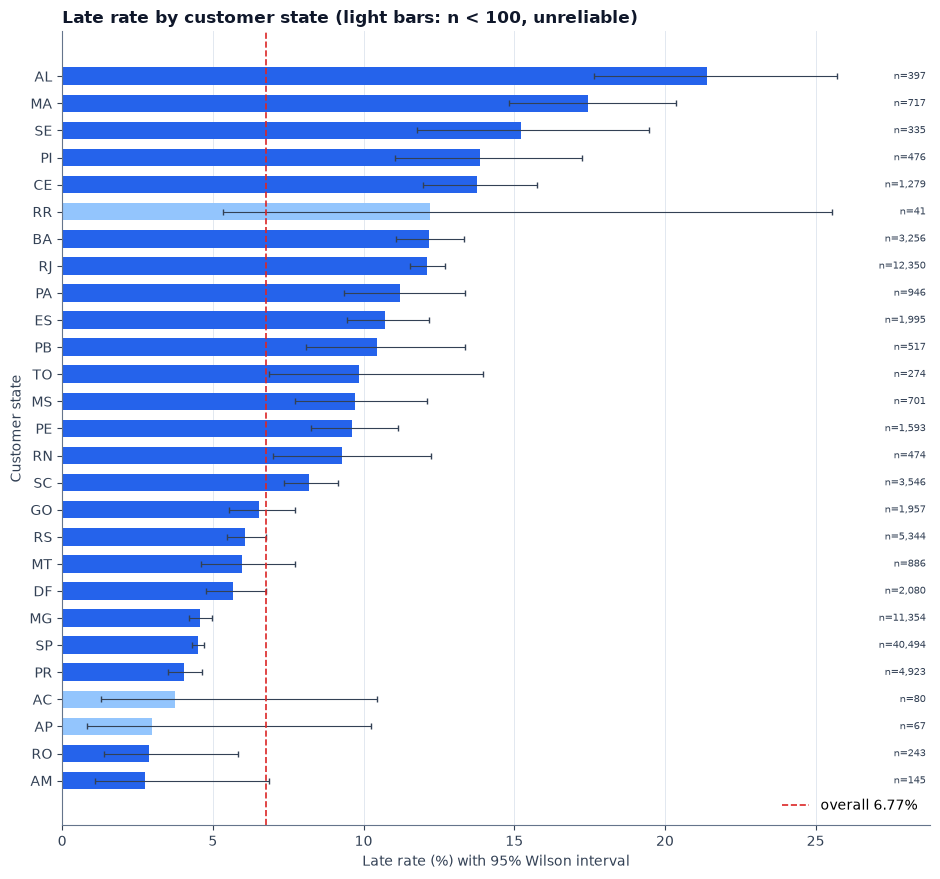

Highest and lowest late rates among states with n >= 100:


,customer_state,n,late,late_rate_pct,ci_low_pct,ci_high_pct,mean_dur,median_dur,mean_promise,reliable
0,AL,397,85,21.411,17.659,25.710,24.544,22.333,33.209,True
1,MA,717,125,17.434,14.832,20.382,21.573,19.191,31.084,True
2,SE,335,51,15.224,11.773,19.464,21.520,18.014,31.484,True
3,PI,476,66,13.866,11.049,17.261,19.457,16.292,30.702,True
4,CE,1279,176,13.761,11.981,15.758,21.267,18.209,32.005,True
5,MG,11354,519,4.571,4.202,4.971,12.009,10.314,25.188,True
6,SP,40494,1820,4.494,4.297,4.701,8.761,7.210,19.776,True
7,PR,4923,199,4.042,3.527,4.629,11.992,10.426,25.252,True
8,RO,243,7,2.881,1.402,5.826,19.372,17.582,39.387,True
9,AM,145,4,2.759,1.078,6.878,26.426,25.875,45.924,True


The five largest states by number of orders:


,customer_state,n,late,late_rate_pct,ci_low_pct,ci_high_pct,mean_dur,median_dur,mean_promise,reliable
0,SP,40494,1820,4.494,4.297,4.701,8.761,7.210,19.776,True
1,RJ,12350,1495,12.105,11.542,12.692,15.309,12.042,26.998,True
2,MG,11354,519,4.571,4.202,4.971,12.009,10.314,25.188,True
3,RS,5344,325,6.082,5.472,6.754,15.300,13.177,29.159,True
4,PR,4923,199,4.042,3.527,4.629,11.992,10.426,25.252,True


States below the sample threshold: [['RR', 41], ['AC', 80], ['AP', 67]]
Spread of late rate across reliable states: 2.76% .. 21.41% (7.8x)
Chi-square, customer_state vs is_late: chi2 = 1785.8, dof = 26, p < 1e-300, Cramer's V = 0.136


In [26]:
st = d.groupby("customer_state", observed=True).agg(n=("is_late", "size"), late=("is_late", "sum"),
                                                   mean_dur=("delivery_duration_days", "mean"),
                                                   median_dur=("delivery_duration_days", "median"),
                                                   mean_promise=("estimated_delivery_days", "mean")).reset_index()
st["late_rate"] = st.late / st.n
st["lo"], st["hi"] = wilson(st.late, st.n)
st["reliable"] = st.n >= MIN_N
st = st.sort_values("late_rate", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.5, 0.27 * len(st) + 1.6))
y = np.arange(len(st))[::-1]
cols = np.where(st.reliable, P["blue"], P["blue_light"])
ax.barh(y, st.late_rate * 100, color=cols, height=.65)
ax.errorbar(st.late_rate * 100, y, xerr=[(st.late_rate - st.lo) * 100, (st.hi - st.late_rate) * 100],
            fmt="none", ecolor=P["slate"], elinewidth=.8, capsize=2)
for yy, (_, r_) in zip(y, st.iterrows()):
    ax.text(0.995, yy, f"n={int(r_.n):,}", va="center", ha="right", fontsize=7.5, color=P["slate"],
            transform=ax.get_yaxis_transform())
ax.set_yticks(y); ax.set_yticklabels(st.customer_state)
ax.axvline(BASE_LATE * 100, color=P["red"], ls="--", lw=1.2, label=f"overall {BASE_LATE:.2%}")
ax.set_xlabel("Late rate (%) with 95% Wilson interval"); ax.set_ylabel("Customer state")
ax.set_title(f"Late rate by customer state (light bars: n < {MIN_N}, unreliable)")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False); ax.set_xlim(0, st.hi.max() * 100 * 1.12)
save_show(fig, "07_late_rate_by_state")

disp = st.assign(late_rate_pct=100 * st.late_rate, ci_low_pct=100 * st.lo, ci_high_pct=100 * st.hi)[
    ["customer_state", "n", "late", "late_rate_pct", "ci_low_pct", "ci_high_pct", "mean_dur", "median_dur", "mean_promise", "reliable"]]
print("Highest and lowest late rates among states with n >= %d:" % MIN_N)
rel = disp[disp.reliable]
display(pd.concat([rel.head(5), rel.tail(5)]).reset_index(drop=True))
print("The five largest states by number of orders:")
display(disp.nlargest(5, "n").reset_index(drop=True))
print("States below the sample threshold:", disp.loc[~disp.reliable, ["customer_state", "n"]].values.tolist())
print(f"Spread of late rate across reliable states: {rel.late_rate_pct.min():.2f}% .. {rel.late_rate_pct.max():.2f}% "
      f"({rel.late_rate_pct.max() / rel.late_rate_pct.min():.1f}x)")
chi = stats.chi2_contingency(pd.crosstab(d.customer_state, d.is_late))
n_ct = pd.crosstab(d.customer_state, d.is_late).values.sum()
cv = np.sqrt(chi.statistic / (n_ct * 1))
print(f"Chi-square, customer_state vs is_late: chi2 = {chi.statistic:.1f}, dof = {chi.dof}, p {'< 1e-300' if chi.pvalue == 0 else '= %.2e' % chi.pvalue}, Cramer's V = {cv:.3f}")

**Interpretation.**

* **Large regional differences.** Among the 24 states with n >= 100 the late rate ranges from **2.76% (AM, n = 145)** to **21.41% (AL, n = 397; 95% CI 17.7–25.7%)**, a 7.8-fold spread. The highest rates are in the North-East: AL 21.4%, MA 17.4% (n = 717), SE 15.2% (n = 335),
  PI 13.9% (n = 476), CE 13.8% (n = 1,279). RJ, the second-largest state (n = 12,350), has a late rate of 12.1%.
* **The big southern/south-eastern states are low:** SP 4.49% (n = 40,494; 42% of all orders), MG 4.57% (n = 11,354), PR 4.04% (n = 4,923), RS 6.08% (n = 5,344).
* **Duration is not lateness.** AL's mean duration is 24.5 days vs 8.8 days in SP, but AM (26.4 days) and RO (19.4 days) have *low* late rates, 2.76% and 2.88%. The mean checkout promise in those states is long (45.9 days AM, 39.4 days RO, vs 33.2 days AL and 19.8 days SP), i.e. the promise appears to
  absorb the longer shipping time there. These two states have small samples (n = 145 and n = 243) and very wide intervals (AM: 1.1–6.9%).
* **Small samples:** RR (n = 41), AC (n = 80) and AP (n = 67) are below the 100-order threshold; their estimates are shown in light blue and must not be ranked.
* **Statistical test:** a chi-square test of `customer_state` vs `is_late` gives chi2 = 1,785.8 (dof 26, p < 1e-300) with Cramér's V = 0.136 — the association is statistically unambiguous with a small-to-moderate effect size. Statistical significance with n = 96k is almost guaranteed;
  the effect size is the useful number. State is an association with, not a cause of, lateness: it stands in for distance, carrier networks and infrastructure, none of which are in the data.

### 4.5 Late rate by product category

74 categories in the analysis set (52 with n >= 100; 22 below the threshold and excluded from ranking)


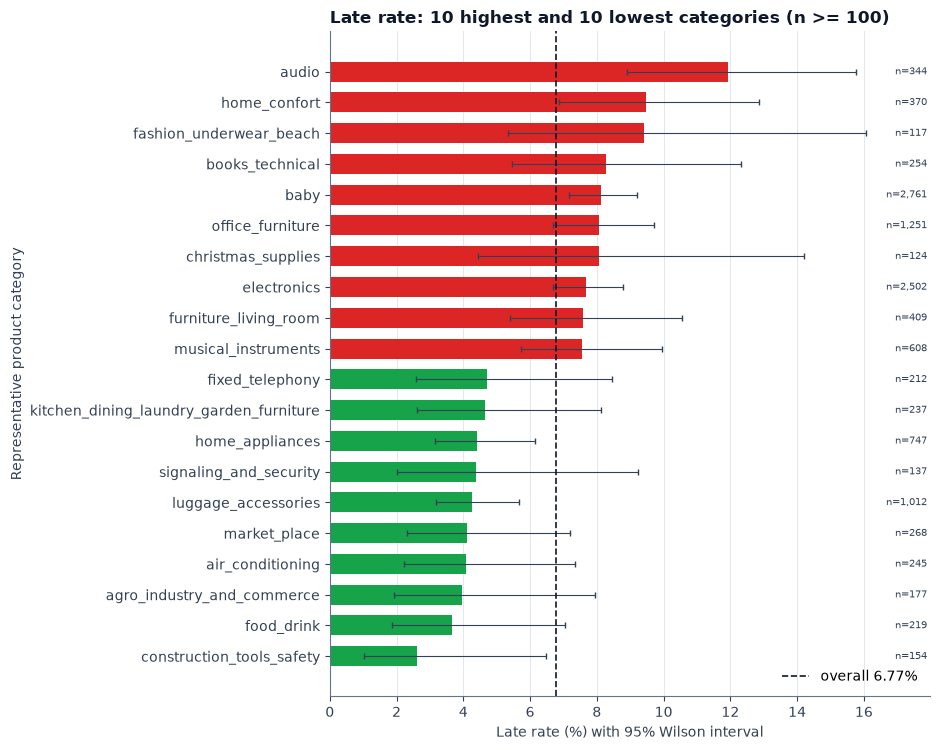

,product_category,n,late,late_rate_pct,ci_low_pct,ci_high_pct,mean_dur
0,audio,344,41,11.919,8.908,15.770,13.466
1,home_confort,370,35,9.459,6.880,12.872,13.631
2,fashion_underwear_beach,117,11,9.402,5.331,16.054,14.003
3,books_technical,254,21,8.268,5.471,12.308,10.669
4,baby,2761,224,8.113,7.152,9.191,12.723
5,market_place,268,11,4.104,2.307,7.199,12.419
6,air_conditioning,245,10,4.082,2.232,7.349,11.909
7,agro_industry_and_commerce,177,7,3.955,1.929,7.937,11.432
8,food_drink,219,8,3.653,1.862,7.041,10.840
9,construction_tools_safety,154,4,2.597,1.015,6.488,11.725


Ten largest categories by n: [['bed_bath_table', 9184, 7.48], ['health_beauty', 8613, 7.54], ['sports_leisure', 7492, 6.59], ['computers_accessories', 6511, 6.4], ['furniture_decor', 6188, 7.24], ['housewares', 5680, 5.42], ['watches_gifts', 5476, 7.41], ['telephony', 4073, 7.14], ['auto', 3792, 7.33], ['toys', 3787, 6.42]]
'unknown' category (missing in source): [{'n': 1358, 'late': 97, 'late_rate_pct': 7.14}]
Categories with n >= 100: 52; 95% interval overlaps the overall 6.77%: 40; entirely above: 5; entirely below: 7 (about 2.6 exclusions expected by chance alone)
Interval excludes overall rate: ['audio (11.92%, n=344)', 'home_confort (9.46%, n=370)', 'baby (8.11%, n=2,761)', 'health_beauty (7.54%, n=8,613)', 'bed_bath_table (7.48%, n=9,184)', 'cool_stuff (5.92%, n=3,530)', 'fashion_bags_accessories (5.58%, n=1,811)', 'housewares (5.42%, n=5,680)', 'pet_shop (5.05%, n=1,682)', 'home_appliances (4.42%, n=747)', 'luggage_accessories (4.25%, n=1,012)', 'construction_tools_safety (2.60

In [27]:
cat = d.groupby("product_category", observed=True).agg(n=("is_late", "size"), late=("is_late", "sum"),
                                                      mean_dur=("delivery_duration_days", "mean")).reset_index()
cat["late_rate"] = cat.late / cat.n
cat["lo"], cat["hi"] = wilson(cat.late, cat.n)
cr = cat[cat.n >= MIN_N].sort_values("late_rate", ascending=False)
print(f"{len(cat)} categories in the analysis set ({len(cr)} with n >= {MIN_N}; {(cat.n < MIN_N).sum()} below the threshold and excluded from ranking)")
k = 10
sel = pd.concat([cr.head(k), cr.tail(k)]).drop_duplicates("product_category")
sel = sel.sort_values("late_rate")
fig, ax = plt.subplots(figsize=(9.5, 0.3 * len(sel) + 1.6))
y = np.arange(len(sel))
ax.barh(y, sel.late_rate * 100, color=[P["red"] if v > BASE_LATE else P["green"] for v in sel.late_rate], height=.65)
ax.errorbar(sel.late_rate * 100, y, xerr=[(sel.late_rate - sel.lo) * 100, (sel.hi - sel.late_rate) * 100],
            fmt="none", ecolor=P["slate"], elinewidth=.8, capsize=2)
for yy, (_, r_) in zip(y, sel.iterrows()):
    ax.text(0.995, yy, f"n={int(r_.n):,}", va="center", ha="right", fontsize=7.5, color=P["slate"],
            transform=ax.get_yaxis_transform())
ax.set_yticks(y); ax.set_yticklabels(sel.product_category)
ax.axvline(BASE_LATE * 100, color=P["navy"], ls="--", lw=1.2, label=f"overall {BASE_LATE:.2%}")
ax.set_xlabel("Late rate (%) with 95% Wilson interval"); ax.set_ylabel("Representative product category")
ax.set_title(f"Late rate: {k} highest and {k} lowest categories (n >= {MIN_N})")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False); ax.set_xlim(0, sel.hi.max() * 100 * 1.12)
save_show(fig, "08_late_rate_by_category")
display(pd.concat([cr.head(5), cr.tail(5)]).assign(late_rate_pct=lambda t: 100 * t.late_rate,
        ci_low_pct=lambda t: 100 * t.lo, ci_high_pct=lambda t: 100 * t.hi)[
        ["product_category", "n", "late", "late_rate_pct", "ci_low_pct", "ci_high_pct", "mean_dur"]].reset_index(drop=True))
print("Ten largest categories by n:", cat.nlargest(10, "n")[["product_category", "n"]].assign(
    late_pct=lambda t: (100 * cat.loc[t.index, "late_rate"]).round(2)).values.tolist())
unk = cat[cat.product_category == "unknown"]
print("'unknown' category (missing in source):", unk[["n", "late"]].assign(late_rate_pct=100 * unk.late / unk.n).round(2).to_dict("records"))
sig_hi = cr[cr.lo > BASE_LATE]; sig_lo = cr[cr.hi < BASE_LATE]
print(f"Categories with n >= {MIN_N}: {len(cr)}; 95% interval overlaps the overall {BASE_LATE:.2%}: {len(cr) - len(sig_hi) - len(sig_lo)}; "
      f"entirely above: {len(sig_hi)}; entirely below: {len(sig_lo)} (about {0.05 * len(cr):.1f} exclusions expected by chance alone)")
print("Interval excludes overall rate:", [f"{r_.product_category} ({r_.late_rate:.2%}, n={int(r_.n):,})" for r_ in pd.concat([sig_hi, sig_lo]).itertuples()])
chi_c = stats.chi2_contingency(pd.crosstab(d.loc[d.product_category.isin(cr.product_category), "product_category"],
                                           d.loc[d.product_category.isin(cr.product_category), "is_late"]))
print(f"Chi-square (categories with n >= {MIN_N}) vs is_late: chi2 = {chi_c.statistic:.1f}, dof = {chi_c.dof}, p = {chi_c.pvalue:.2e}, "
      f"Cramer's V = {np.sqrt(chi_c.statistic / cr.n.sum()):.3f}")

**Interpretation.** 74 categories occur in the analysis set; 52 have at least 100 orders and are ranked (22 are too small).

* The highest late rates are in **audio (11.92%, n = 344)**, home_confort (9.46%, n = 370), fashion_underwear_beach (9.40%, n = 117), books_technical (8.27%, n = 254) and baby (8.11%, n = 2,761). The lowest are construction_tools_safety (2.60%, n = 154),
  food_drink (3.65%, n = 219) and agro_industry_and_commerce (3.96%, n = 177).
* **Most intervals overlap the overall 6.77% line, but not all:** for 40 of 52 categories the 95% interval overlaps the overall rate; 12 differ detectably (interval entirely above or below it), e.g. audio, home_confort, baby (95% CI 7.2–9.2%), health_beauty, bed_bath_table and housewares (about 2–3 exclusions would be expected by chance alone). The chi-square test across categories agrees (chi2 = 142.4, dof 51, p ≈ 1.4e-10), but all differences are small: Cramér's V is only **0.039** —
  category explains far less than customer state (V = 0.136).
* The ten largest categories (bed_bath_table n = 9,184, 7.48%; health_beauty n = 8,613, 7.54%; sports_leisure, computers_accessories, furniture_decor, housewares) (plus watches_gifts, telephony, auto, toys) all sit between 5.42% (housewares) and 7.54% (health_beauty). The 1,358 orders with an *unknown* category are close to the average (7.14%).
* Caveat: we look at 52 categories at once, so a few apparent extremes are expected by chance; the category shown is the *representative* (highest-priced item's) category.

### 4.6 Weight, freight and delivery duration

,total_weight_g from,to,n,mean_dur,median_dur,late_rate_pct
0,2.000,175.000,10011,11.720,9.480,6.360
1,176.000,250.000,10481,11.590,9.400,5.820
2,251.000,350.000,8601,12.340,9.930,7.590
3,351.000,500.000,9730,12.280,10.000,6.520
4,501.000,750.000,9953,12.300,10.060,6.200
5,752.000,"1,100.000",9102,12.420,10.210,6.300
6,"1,103.000","1,650.000",10068,12.820,10.460,7.210
7,"1,651.000","2,800.000",9351,12.730,10.430,6.830
8,"2,804.000","6,550.000",9524,13.180,10.890,7.130
9,"6,575.000","184,400.000",9627,14.310,11.780,7.960


total_weight_g: n with value = 96,448  | Spearman rho vs duration = 0.087, vs is_late = 0.016


,total_freight from,to,n,mean_dur,median_dur,late_rate_pct
0,0.000,9.340,9853,5.920,4.820,4.240
1,9.350,12.830,9544,8.840,7.290,4.600
2,12.840,14.530,9572,10.560,8.850,5.250
3,14.540,15.640,9620,12.730,10.830,6.830
4,15.650,17.170,9655,13.850,11.770,7.580
5,17.180,18.590,9725,14.050,11.910,7.630
6,18.600,21.960,9564,14.120,11.760,7.850
7,21.970,27.380,9661,14.440,12.030,7.510
8,27.390,39.380,9629,15.290,12.970,7.760
9,39.390,"1,794.960",9647,15.870,13.200,8.490


total_freight: n with value = 96,470  | Spearman rho vs duration = 0.382, vs is_late = 0.052


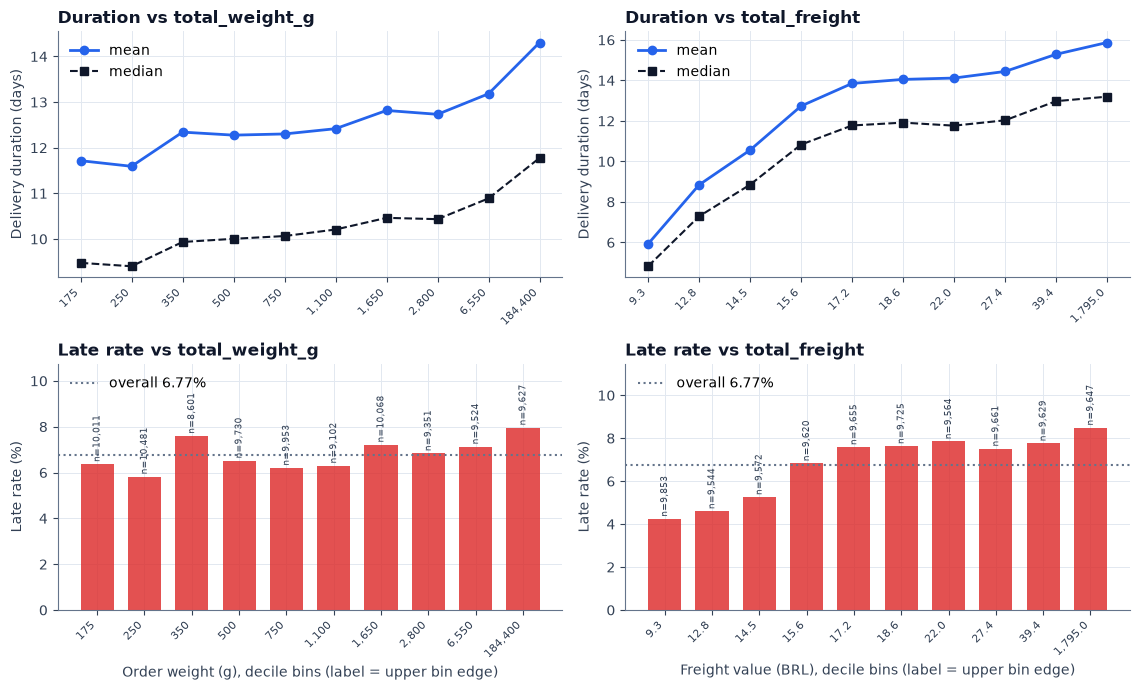

In [28]:
def binned(df: pd.DataFrame, col: str, q: int = 10) -> pd.DataFrame:
    """Quantile bins of ``col`` with n, mean/median duration and late rate per bin (NaNs dropped)."""
    s = df[[col, "delivery_duration_days", "is_late"]].dropna()
    b = pd.qcut(s[col], q=q, duplicates="drop")
    g = s.groupby(b, observed=True).agg(n=("is_late", "size"), late=("is_late", "sum"),
                                        mean_dur=("delivery_duration_days", "mean"),
                                        median_dur=("delivery_duration_days", "median"),
                                        lo_edge=(col, "min"), hi_edge=(col, "max")).reset_index(drop=True)
    g["late_rate"] = g.late / g.n
    return g

fig, axes = plt.subplots(2, 2, figsize=(11.5, 7))
for j, (col, lab, fmt) in enumerate([("total_weight_g", "Order weight (g), decile bins", "{:,.0f}"),
                                      ("total_freight", "Freight value (BRL), decile bins", "{:,.1f}")]):
    g = binned(d, col)
    xs = np.arange(len(g))
    labels = [fmt.format(v) for v in g.hi_edge]
    axes[0, j].plot(xs, g.mean_dur, marker="o", color=P["blue"], lw=2, label="mean")
    axes[0, j].plot(xs, g.median_dur, marker="s", color=P["navy"], lw=1.5, ls="--", label="median")
    axes[0, j].set_ylabel("Delivery duration (days)"); axes[0, j].set_title(f"Duration vs {col}")
    axes[0, j].legend(); axes[0, j].set_xticks(xs); axes[0, j].set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    axes[1, j].bar(xs, g.late_rate * 100, color=P["red"], alpha=.8, width=.7)
    axes[1, j].axhline(BASE_LATE * 100, color=P["slate_light"], ls=":", label=f"overall {BASE_LATE:.2%}")
    for xx, (lr, nn) in enumerate(zip(g.late_rate, g.n)):
        axes[1, j].text(xx, lr * 100 + .1, f"n={nn:,}", ha="center", fontsize=6.5, rotation=90, va="bottom", color=P["slate"])
    axes[1, j].set_ylabel("Late rate (%)"); axes[1, j].set_xlabel(f"{lab} (label = upper bin edge)")
    axes[1, j].set_ylim(0, g.late_rate.max() * 100 * 1.35); axes[1, j].legend(loc="upper left")
    axes[1, j].set_xticks(xs); axes[1, j].set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    axes[1, j].set_title(f"Late rate vs {col}")
    display(g.assign(late_rate_pct=100 * g.late_rate)[["lo_edge", "hi_edge", "n", "mean_dur", "median_dur", "late_rate_pct"]]
            .rename(columns={"lo_edge": f"{col} from", "hi_edge": "to"}).round(2))
    print(f"{col}: n with value = {d[col].notna().sum():,}  | Spearman rho vs duration = "
          f"{stats.spearmanr(d[col], d.delivery_duration_days, nan_policy='omit').statistic:.3f}, "
          f"vs is_late = {stats.spearmanr(d[col], d.is_late.astype(float), nan_policy='omit').statistic:.3f}")
save_show(fig, "09_weight_freight_vs_duration")

**Interpretation (associations only).**

* **Weight:** mean duration rises gently from 11.7 days (lightest decile, up to 175 g) to 14.3 days (heaviest decile, above 6,575 g); the late rate wanders between 5.82% and 7.96% without a clean trend, with about 8,600–10,500 orders in each bin.
  Spearman rho is **0.087** with duration and **0.016** with `is_late`: weak.
* **Freight:** a much stronger relationship with duration: mean duration is 5.9 days in the cheapest freight decile (up to BRL 9.34) and 15.9 days in the most expensive (above BRL 39.39), Spearman rho = **0.382**. The late rate rises from 4.24% to 8.49%, but the rank correlation with `is_late`
  is only **0.052**.
* Freight value in this data reflects, among other things, weight *and shipping distance*, so it very likely acts as a proxy for geography (consistent with the state results). We cannot separate these effects here, and the pattern says nothing about what would happen if freight were changed.
* Note that `estimated_delivery_days` has rho = 0.523 with duration but −0.023 with `is_late` (section 4.9): the promise already scales with expected duration, which is why longer deliveries are not much *later* deliveries.

### 4.7 Seller processing time (RETROSPECTIVE)

processing_days (RETROSPECTIVE: carrier pickup - purchase) available for 96,304 of 96,470 orders (166 NaN: carrier date missing/invalid)


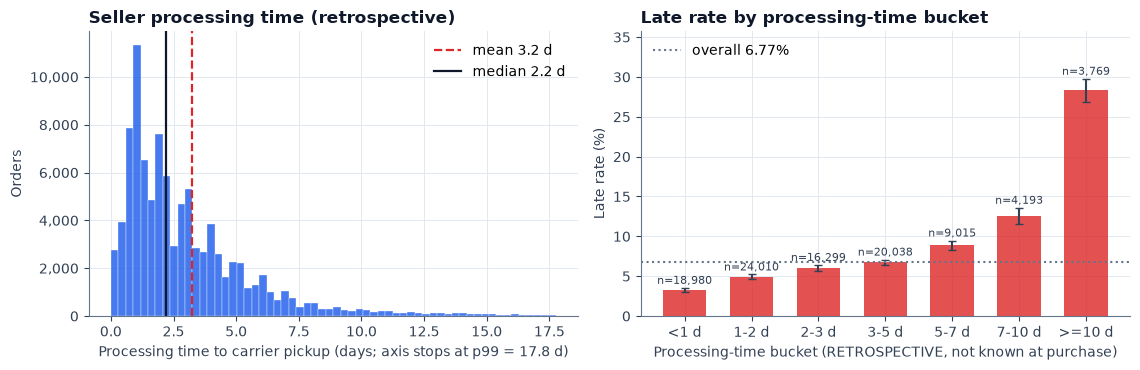

,bucket,n,late,late_rate_pct
0,<1 d,18980,621,3.270
1,1-2 d,24010,1185,4.940
2,2-3 d,16299,984,6.040
3,3-5 d,20038,1348,6.730
4,5-7 d,9015,800,8.870
5,7-10 d,4193,526,12.540
6,>=10 d,3769,1067,28.310


Spearman rho(processing_days, is_late) = 0.131
Share of total duration spent after carrier pickup (mean of carrier_to_customer / duration): 70.5%


In [29]:
pr = d.processing_days.dropna()
print(f"processing_days (RETROSPECTIVE: carrier pickup - purchase) available for {len(pr):,} of {N:,} orders "
      f"({N - len(pr):,} NaN: carrier date missing/invalid)")
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
hi = pr.quantile(.99)
axes[0].hist(pr, bins=60, range=(0, hi), color=P["blue"], alpha=.85, edgecolor="white", linewidth=.3)
axes[0].axvline(pr.mean(), color=P["red"], ls="--", lw=1.6, label=f"mean {pr.mean():.1f} d")
axes[0].axvline(pr.median(), color=P["navy"], lw=1.6, label=f"median {pr.median():.1f} d")
axes[0].set_xlabel(f"Processing time to carrier pickup (days; axis stops at p99 = {hi:.1f} d)")
axes[0].set_ylabel("Orders"); axes[0].set_title("Seller processing time (retrospective)"); axes[0].legend()
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

bk = pd.cut(d.processing_days, [0, 1, 2, 3, 5, 7, 10, np.inf], right=False,
            labels=["<1 d", "1-2 d", "2-3 d", "3-5 d", "5-7 d", "7-10 d", ">=10 d"])
pb = d.groupby(bk, observed=True).agg(n=("is_late", "size"), late=("is_late", "sum")).reset_index().rename(columns={"processing_days": "bucket"})
pb["late_rate"] = pb.late / pb.n
pb["lo"], pb["hi"] = wilson(pb.late, pb.n)
axes[1].bar(pb.bucket.astype(str), pb.late_rate * 100, color=P["red"], alpha=.8, width=.65)
axes[1].errorbar(pb.bucket.astype(str), pb.late_rate * 100, yerr=[(pb.late_rate - pb.lo) * 100, (pb.hi - pb.late_rate) * 100],
                 fmt="none", ecolor=P["slate"], capsize=3)
for xx, (lr, h_, nn) in enumerate(zip(pb.late_rate, pb.hi, pb.n)):
    axes[1].text(xx, h_ * 100 + .5, f"n={nn:,}", ha="center", fontsize=8, color=P["slate"])
axes[1].axhline(BASE_LATE * 100, color=P["slate_light"], ls=":", label=f"overall {BASE_LATE:.2%}")
axes[1].set_xlabel("Processing-time bucket (RETROSPECTIVE, not known at purchase)"); axes[1].set_ylabel("Late rate (%)")
axes[1].set_title("Late rate by processing-time bucket"); axes[1].legend(loc="upper left")
axes[1].set_ylim(0, pb.hi.max() * 100 * 1.2)
save_show(fig, "10_processing_time")
display(pb.assign(late_rate_pct=(100 * pb.late_rate).round(2))[["bucket", "n", "late", "late_rate_pct"]])
print("Spearman rho(processing_days, is_late) =", round(stats.spearmanr(d.processing_days, d.is_late.astype(float), nan_policy="omit").statistic, 3))
cc = d[["processing_days", "carrier_to_customer_days", "delivery_duration_days"]].dropna()
print("Share of total duration spent after carrier pickup (mean of carrier_to_customer / duration):",
      f"{(cc.carrier_to_customer_days / cc.delivery_duration_days).mean():.1%}")

**Interpretation (RETROSPECTIVE: carrier pickup is only known after the order is placed).**

* `processing_days` (purchase → carrier pickup) is available for 96,304 of 96,470 orders (166 are NaN: carrier date missing or before purchase). Mean 3.2 days, median 2.2 days, with a long tail.
* The late rate rises steeply with processing time: **3.27% (< 1 day, n = 18,980)** → 6.04% (2–3 days, n = 16,299) → 12.54% (7–10 days, n = 4,193) → **28.31% (>= 10 days, n = 3,769)**. Spearman rho with `is_late` = 0.131.
* This is partly mechanical: processing time is a *component* of the total duration, so slow processing contributes directly to a late arrival. On average **70.5%** of the total duration happens *after* carrier pickup, so transit still dominates.
* Because this information does not exist when the customer clicks "buy", it is an operations/seller-performance diagnostic and **cannot** be a predictor of purchase-time risk (section 5).

### 4.8 Same-state vs cross-state shipments

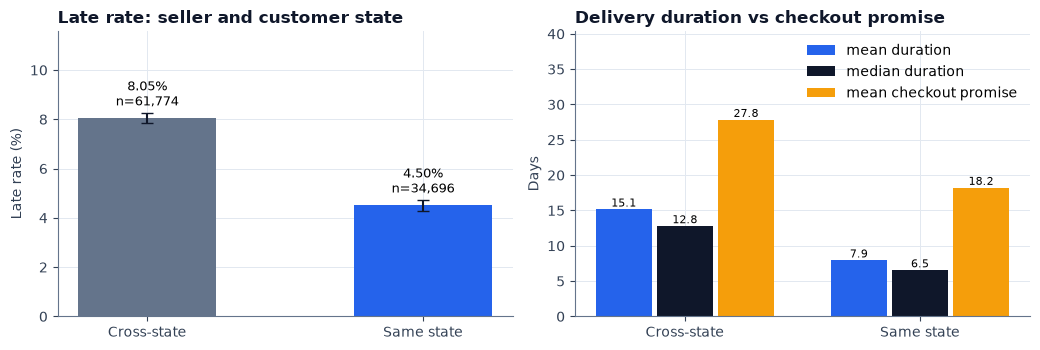

,group,n,late,late_rate_pct,ci_low_pct,ci_high_pct,mean_dur,median_dur,mean_promise
0,Cross-state,61774,4971,8.050,7.840,8.260,15.150,12.790,27.830
1,Same state,34696,1563,4.500,4.290,4.730,7.940,6.550,18.220


Chi-square same_state vs is_late: chi2 = 440.9, p = 6.80e-98, Cramer's V = 0.068

Most common seller->customer state pairs (top 6 by n) and the highest late rates among pairs with n >= 100:


,state_pair,n,late,late_rate_pct
0,SP→SP,30727,1428,4.647
1,SP→RJ,8155,1152,14.126
2,SP→MG,7437,393,5.284
3,SP→RS,3594,238,6.622
4,SP→PR,3117,138,4.427
5,PR→SP,2925,90,3.077


,state_pair,n,late,late_rate_pct
0,SP→AL,255,61,23.922
1,MA→SP,123,25,20.325
2,SP→MA,492,93,18.902
3,SP→PI,329,54,16.413
4,SP→SE,208,34,16.346


In [30]:
ss = d.groupby("same_state").agg(n=("is_late", "size"), late=("is_late", "sum"), mean_dur=("delivery_duration_days", "mean"),
                                 median_dur=("delivery_duration_days", "median"),
                                 mean_promise=("estimated_delivery_days", "mean")).reset_index()
ss["late_rate"] = ss.late / ss.n
ss["lo"], ss["hi"] = wilson(ss.late, ss.n)
ss["group"] = ss.same_state.map({1: "Same state", 0: "Cross-state"})
ss = ss.sort_values("same_state")
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
axes[0].bar(ss.group, ss.late_rate * 100, color=[P["slate_light"], P["blue"]], width=.5)
axes[0].errorbar(ss.group, ss.late_rate * 100, yerr=[(ss.late_rate - ss.lo) * 100, (ss.hi - ss.late_rate) * 100],
                 fmt="none", ecolor=P["navy"], capsize=4)
for xx, r_ in enumerate(ss.itertuples()):
    axes[0].text(xx, r_.hi * 100 + .3, f"{r_.late_rate:.2%}\nn={r_.n:,}", ha="center", fontsize=9)
axes[0].set_ylabel("Late rate (%)"); axes[0].set_title("Late rate: seller and customer state"); axes[0].set_ylim(0, ss.hi.max() * 100 * 1.4)
xx = np.arange(len(ss)); wdt = .26
for off, col, lab, c_ in [(-wdt, "mean_dur", "mean duration", P["blue"]), (0, "median_dur", "median duration", P["navy"]),
                          (wdt, "mean_promise", "mean checkout promise", P["amber"])]:
    axes[1].bar(xx + off, ss[col], width=wdt - .02, color=c_, label=lab)
    for x_, v_ in zip(xx + off, ss[col]):
        axes[1].text(x_, v_ + .4, f"{v_:.1f}", ha="center", fontsize=8)
axes[1].set_xticks(xx); axes[1].set_xticklabels(ss.group)
axes[1].set_ylabel("Days"); axes[1].set_title("Delivery duration vs checkout promise"); axes[1].legend(loc="upper right")
axes[1].set_ylim(0, ss.mean_promise.max() * 1.45)
save_show(fig, "11_same_vs_cross_state")
display(ss.assign(late_rate_pct=100 * ss.late_rate, ci_low_pct=100 * ss.lo, ci_high_pct=100 * ss.hi)[
    ["group", "n", "late", "late_rate_pct", "ci_low_pct", "ci_high_pct", "mean_dur", "median_dur", "mean_promise"]].round(2))
ct = pd.crosstab(d.same_state, d.is_late)
c2 = stats.chi2_contingency(ct)
print(f"Chi-square same_state vs is_late: chi2 = {c2.statistic:.1f}, p = {c2.pvalue:.2e}, Cramer's V = {np.sqrt(c2.statistic / ct.values.sum()):.3f}")

pairs = d.groupby("state_pair", observed=True).agg(n=("is_late", "size"), late=("is_late", "sum")).reset_index()
pairs["late_rate_pct"] = 100 * pairs.late / pairs.n
print(f"\nMost common seller->customer state pairs (top 6 by n) and the highest late rates among pairs with n >= {MIN_N}:")
display(pairs.nlargest(6, "n").reset_index(drop=True))
display(pairs[pairs.n >= MIN_N].nlargest(5, "late_rate_pct").reset_index(drop=True))

**Interpretation.**

* **35.97%** of analysis orders are same-state (representative seller and customer in the same state). Their late rate is **4.50% (n = 34,696; 95% CI 4.29–4.73%)** vs **8.05% (n = 61,774; 7.84–8.26%)** for cross-state orders.
* Mean duration is 7.9 vs 15.1 days (median 6.5 vs 12.8), and the checkout promise is 18.2 vs 27.8 days: the promise grows with distance, but not enough to offset the higher late rate.
* chi-square: chi2 = 440.9, p = 6.8e-98, Cramér's V = **0.068** (small effect). The gap is real in this sample, but "cross-state" is another proxy for distance/logistics, not a cause that we can isolate.
* **State pairs:** SP→SP (n = 30,727) has a late rate of 4.65%; the next biggest flow SP→RJ (n = 8,155) has **14.13%**, SP→MG (n = 7,437) 5.28%, SP→RS (n = 3,594) 6.62%. Among pairs with n >= 100, the highest rates are SP→AL 23.92% (n = 255),
  MA→SP 20.33% (n = 123), SP→MA 18.90% (n = 492). Most sellers are in SP, so "same-state" is dominated by SP→SP.

### 4.9 Summary statistics and rank correlations with purchase-time features

,count,mean,std,min,5%,25%,50%,75%,95%,max,missing,skew
delivery_duration_days,"96,470.000",12.558,9.546,0.533,3.015,6.766,10.217,15.720,29.274,209.629,0,3.833
delivery_delay_days,"96,470.000",-11.876,10.182,-147.000,-26.000,-17.000,-12.000,-7.000,3.000,188.000,0,2.016
estimated_delivery_days,"96,470.000",24.373,8.758,3.000,11.000,19.000,24.000,29.000,39.000,156.000,0,0.905
total_price,"96,470.000",137.040,209.053,0.850,19.000,45.900,86.500,149.900,399.000,"13,440.000",0,9.885
total_freight,"96,470.000",22.786,21.560,0.000,7.880,13.850,17.170,24.020,54.780,"1,794.960",0,12.277
freight_ratio,"96,470.000",0.308,0.312,0.000,0.054,0.132,0.224,0.381,0.839,21.447,0,9.671
total_weight_g,"96,448.000","2,387.017","4,770.221",2.000,147.000,300.000,750.000,"2,050.000","10,500.000","184,400.000",22,6.572
total_volume_cm3,"96,454.000","17,331.937","30,143.871",168.000,816.000,"2,964.000","7,254.000","19,866.000","64,000.000","1,476,000.000",16,7.358
n_items,"96,470.000",1.142,0.539,1.000,1.000,1.000,1.000,1.000,2.000,21.000,0,7.558
processing_days,"96,304.000",3.235,3.554,0.000,0.463,1.130,2.205,4.071,8.877,125.776,166,4.914


,feature,n,rho_vs_duration,rho_vs_is_late
0,total_freight,96470,0.382,0.052
1,purchase_month,96470,-0.071,-0.040
2,n_sellers,96470,-0.048,-0.027
3,total_price,96470,0.102,0.024
4,estimated_delivery_days,96470,0.523,-0.023
5,n_items,96470,-0.025,-0.020
6,total_weight_g,96448,0.087,0.016
7,purchase_dow,96470,0.048,-0.012
8,max_product_length_cm,96454,0.071,0.010
9,max_product_height_cm,96454,0.051,0.010


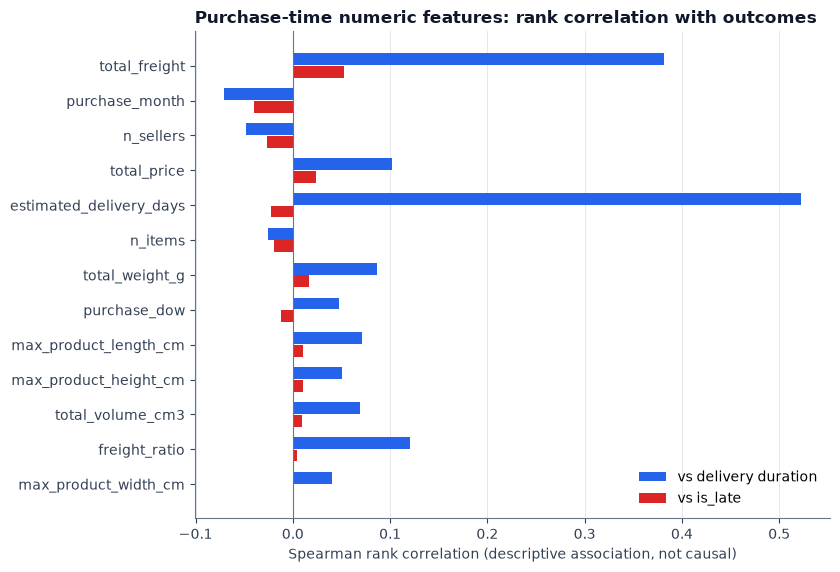

In [31]:
num_cols = ["delivery_duration_days", "delivery_delay_days", "estimated_delivery_days", "total_price", "total_freight",
            "freight_ratio", "total_weight_g", "total_volume_cm3", "n_items", "processing_days", "review_score"]
summ = d[num_cols].astype(float).describe(percentiles=[.05, .25, .5, .75, .95]).T
summ["missing"] = d[num_cols].isna().sum().values
summ["skew"] = d[num_cols].astype(float).skew()
display(summ)

# Spearman association of purchase-time numeric features with outcomes (descriptive)
feat = [c for c in config.PURCHASE_TIME_NUMERIC if c not in ("purchase_quarter",)]
rows = []
for c in feat:
    s = d[[c, "delivery_duration_days", "is_late"]].dropna().astype(float)
    rows.append({"feature": c, "n": len(s),
                 "rho_vs_duration": stats.spearmanr(s[c], s.delivery_duration_days).statistic,
                 "rho_vs_is_late": stats.spearmanr(s[c], s.is_late).statistic})
sp = pd.DataFrame(rows).sort_values("rho_vs_is_late", key=abs, ascending=False).reset_index(drop=True)
display(sp)
fig, ax = plt.subplots(figsize=(8.5, 0.34 * len(sp) + 1.4))
y = np.arange(len(sp))[::-1]
ax.barh(y + .18, sp.rho_vs_duration, height=.34, color=P["blue"], label="vs delivery duration")
ax.barh(y - .18, sp.rho_vs_is_late, height=.34, color=P["red"], label="vs is_late")
ax.set_yticks(y); ax.set_yticklabels(sp.feature); ax.axvline(0, color=P["slate_light"], lw=.8)
ax.set_xlabel("Spearman rank correlation (descriptive association, not causal)")
ax.set_title("Purchase-time numeric features: rank correlation with outcomes"); ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save_show(fig, "12_spearman_purchase_time_features")

**Interpretation.**

* The summary table confirms strong right skew in the money and size variables (e.g. skewness of 9.9 for `total_price`, 12.3 for `total_freight`, 6.6 for `total_weight_g`): a median-based imputation and robust or tree-based models are better choices than linear models on raw values.
  `review_score` (mean 4.16 among 95,824 orders with a review; 646 missing) is skewed the other way (−1.48).
* **Rank correlations:** the strongest purchase-time numeric association with *duration* is the checkout promise `estimated_delivery_days` (rho = 0.523) followed by `total_freight` (0.382). For *lateness*, **no numeric purchase-time feature has |rho| above 0.052** (`total_freight` 0.052,
  `purchase_month` −0.040, `n_sellers` −0.027). Individually the numeric features are weak signals of lateness; a model must exploit geography, timing and interactions, and we should expect only modest predictive power.
* These correlations are descriptive; with n = 96k even tiny correlations are "significant", so we judge by size rather than p-values.

## 5. Predictive vs descriptive feature sets: the data-leakage warning

The dashboard answers two different questions, and they need different columns:

* **Descriptive / retrospective analytics** ("what happened and where?") may use *every* column, including delivery timestamps, processing time and review score.
* **Predictive risk** ("how likely is this order to be late, at the moment of purchase?") may use **only information that exists when the order is placed**.

`src/config.py` encodes this split as three disjoint lists that the training script and the tests enforce:

* `PURCHASE_TIME_FEATURES` — the allow-list of model inputs: order size/price/freight/weight/volume aggregates, `estimated_delivery_days` (the checkout promise), purchase month / weekday / quarter, customer state, seller state, representative product category and `same_state`.
* `LEAKAGE_COLUMNS` — deny-list: final status, post-purchase timestamps, durations and delays, processing time, review score, eligibility and exclusion bookkeeping, and flags derived from post-purchase timestamps. These either **are** the outcome or only exist after it.
* `NON_FEATURE_COLUMNS` / `PURCHASE_TIME_UNUSED` — keys, raw timestamps used for the chronological split, time-drift proxies, and purchase-time columns deliberately left out (high-cardinality cities, data-quality flags, secondary counts).

| Group | Example columns | Known at purchase? | Used by the model? |
|---|---|---|---|
| Purchase-time features | `estimated_delivery_days`, `total_freight`, `total_weight_g`, `customer_state`, `seller_state`, `product_category`, `same_state`, `purchase_month` | Yes | Allowed |
| Leakage / outcome | `delivery_delay_days`, `delivery_duration_days`, `processing_days`, `carrier_to_customer_days`, `review_score`, `order_status`, `is_late` | **No** | **Never** |
| Non-feature / unused | `order_id`, raw timestamps, `purchase_year_month`, `customer_city`, `state_pair` | Mixed | No |

The code below assigns **every processed column** to exactly one group (the notebook fails if a column is unclassified), and then makes the danger visible: a *single* column used as a score for `is_late`.

In [32]:
reason = {
    "order_id": "identifier", "order_purchase_timestamp": "raw timestamp; used for the chronological split",
    "order_estimated_delivery_date": "raw timestamp; its information enters via estimated_delivery_days",
    "purchase_date": "date proxy -> time-drift shortcut", "purchase_year": "time-drift proxy",
    "purchase_year_month": "time-drift proxy",
    "order_status": "final status is only known after the order ends", "order_approved_at": "post-purchase event",
    "order_delivered_carrier_date": "post-purchase event", "order_delivered_customer_date": "defines the outcome",
    "delivery_duration_days": "outcome (derived from delivery date)", "delivery_delay_days": "the target before thresholding",
    "processing_days": "known only once the seller ships", "approval_days": "known only once payment is approved",
    "carrier_to_customer_days": "known only after delivery", "is_late": "the target itself",
    "review_score": "written after delivery", "analysis_eligible": "depends on the outcome being observed",
    "exclusion_reason": "depends on the outcome being observed",
    "carrier_date_invalid": "flag from a post-purchase timestamp", "approval_missing": "flag from a post-purchase timestamp",
}
def group_of(c: str) -> str:
    if c in config.PURCHASE_TIME_FEATURES: return "purchase-time feature (allowed)"
    if c in config.LEAKAGE_COLUMNS: return "LEAKAGE / outcome (never a model input)"
    if c in config.PURCHASE_TIME_UNUSED: return "purchase-time, not used by the model"
    if c in config.NON_FEATURE_COLUMNS: return "non-feature (key / split / drift proxy)"
    return "UNCLASSIFIED"

feature_table = pd.DataFrame({"column": list(proc.columns)})
feature_table["group"] = feature_table.column.map(group_of)
feature_table["note"] = feature_table.column.map(lambda c: reason.get(c, "known when the order is placed" if group_of(c).startswith("purchase") else ""))
assert "UNCLASSIFIED" not in set(feature_table.group), "a processed column is not classified in config.py"
assert not set(config.PURCHASE_TIME_FEATURES) & set(config.LEAKAGE_COLUMNS)
display(feature_table.groupby("group").column.agg(["count", lambda s: ", ".join(s)]).rename(
    columns={"count": "n_columns", "<lambda_0>": "columns"}))
print("Every processed column falls in exactly one group (checked).")

,n_columns,columns
group,,
LEAKAGE / outcome (never a model input),15,"order_status, analysis_eligible, exclusion_rea..."
non-feature (key / split / drift proxy),6,"order_id, order_purchase_timestamp, order_esti..."
purchase-time feature (allowed),18,"purchase_month, purchase_quarter, purchase_dow..."
"purchase-time, not used by the model",7,"category_missing, weight_missing, customer_cit..."


Every processed column falls in exactly one group (checked).


In [33]:
# Single-feature ROC-AUC against is_late: a descriptive way to *see* leakage. NOT model performance.
y = d.is_late.astype(int)
def auc1(col: str) -> float:
    s = d[col].astype(float)
    m = s.notna()
    return roc_auc_score(y[m], s[m])

cand = ["delivery_delay_days", "delivery_duration_days", "carrier_to_customer_days", "processing_days", "review_score",
        "estimated_delivery_days", "total_freight", "freight_ratio", "total_weight_g", "same_state", "n_sellers", "total_price"]
leak = pd.DataFrame({"column": cand, "group": [group_of(c) for c in cand],
                     "n_used": [int(d[c].notna().sum()) for c in cand],
                     "AUC_as_score": [auc1(c) for c in cand]})
leak["strength |AUC-0.5|"] = (leak.AUC_as_score - .5).abs()
display(leak.sort_values("strength |AUC-0.5|", ascending=False).reset_index(drop=True))

,column,group,n_used,AUC_as_score,strength |AUC-0.5|
0,delivery_delay_days,LEAKAGE / outcome (never a model input),96470,1.000,0.500
1,delivery_duration_days,LEAKAGE / outcome (never a model input),96470,0.947,0.447
2,carrier_to_customer_days,LEAKAGE / outcome (never a model input),96446,0.896,0.396
3,review_score,LEAKAGE / outcome (never a model input),95824,0.181,0.319
4,processing_days,LEAKAGE / outcome (never a model input),96304,0.651,0.151
5,same_state,purchase-time feature (allowed),96470,0.435,0.065
6,total_freight,purchase-time feature (allowed),96470,0.560,0.060
7,total_price,purchase-time feature (allowed),96470,0.528,0.028
8,estimated_delivery_days,purchase-time feature (allowed),96470,0.474,0.026
9,total_weight_g,purchase-time feature (allowed),96448,0.519,0.019


**Interpretation (this is not model performance, only the univariate ROC-AUC of each column used as a raw score; 0.5 = no information, values far below 0.5 mean the reverse ordering is informative).**

* `delivery_delay_days` has **AUC = 1.000** — by construction, because `is_late` is just "delay > 0". `delivery_duration_days` (0.947), `carrier_to_customer_days` (0.896), `review_score` (0.181, i.e. 0.819 when reversed: late orders get lower scores)
  and `processing_days` (0.651) are all strongly informative **after the fact**.
* The purchase-time columns are far weaker: the best are `same_state` (0.435, i.e. 0.565 reversed), `total_freight` (0.560), `total_price` (0.528), `estimated_delivery_days` (0.474).
* A model trained with any post-purchase column would look excellent in a notebook and be useless in the live "Delay Prediction" page, where those values do not yet exist. Conversely, the weak single-feature signals above set the expectation that a *honest* model will
  be only moderately predictive; a near-perfect validation score would be a red flag for leakage, not a success.
* `estimated_delivery_days` is allowed because the estimated date is shown to the customer at checkout. Its raw timestamp is **not** a feature (it is a split key), and `delivery_delay_days` (delivery − estimate) is not allowed because it contains the delivery date.

In [34]:
vals = {
    "analysis_set_orders": N, "late_orders": int(d.is_late.sum()), "late_rate": BASE_LATE,
    "late_rate_timestamp_basis": float(ts_late.mean()),
    "mean_duration_d": float(d.delivery_duration_days.mean()), "median_duration_d": float(d.delivery_duration_days.median()),
    "p95_duration_d": float(d.delivery_duration_days.quantile(.95)),
    "median_delay_d": float(d.delivery_delay_days.astype(int).median()),
    "mean_promise_d": float(d.estimated_delivery_days.mean()),
    "same_state_share": float(d.same_state.mean()),
    "late_rate_same_state": float(d.loc[d.same_state == 1, "is_late"].astype(int).mean()),
    "late_rate_cross_state": float(d.loc[d.same_state == 0, "is_late"].astype(int).mean()),
    "state_late_rate_min_reliable": float(rel.late_rate_pct.min()), "state_late_rate_max_reliable": float(rel.late_rate_pct.max()),
    "highest_state": rel.iloc[0].customer_state, "lowest_state": rel.iloc[-1].customer_state,
    "highest_month": mon[mon.reliable].nlargest(1, "late_rate").purchase_year_month.iloc[0],
    "highest_month_rate": float(mon[mon.reliable].late_rate.max()),
}
pd.Series(vals).to_frame("value")

,value
analysis_set_orders,96470
late_orders,6534
late_rate,0.068
late_rate_timestamp_basis,0.081
mean_duration_d,12.558
median_duration_d,10.217
p95_duration_d,29.274
median_delay_d,-12.000
mean_promise_d,24.373
same_state_share,0.360


## 6. Key takeaways, limitations and next steps

### Key takeaways (all numbers from the executed cells above)
1. **Analysis set:** 96,470 delivered orders (97.0% of 99,441), purchases from 2016-09-15 to 2018-08-29; **6,534 late (6.77%)** by the calendar-date rule (8.11% if a timestamp comparison were used — the difference is exactly the 1,292 orders delivered on the promised date).
2. **Delivery is usually early:** mean duration 12.6 days (median 10.2, p95 29.3) against a mean promise of 24.4 days; 91.9% of orders arrive before the estimated date. Lateness is a tail event with a heavy class imbalance (13.8 : 1).
3. **Lateness is non-stationary:** monthly late rate from ~3% (May–Oct 2017) to 12.4% (Nov 2017), 14.1% (Feb 2018) and **19.0% (Mar 2018)**, then back to 4.5% in Apr 2018. Nov 24, 2017 alone had 1,147 orders. 2016 has only 267 eligible orders.
4. **Geography is associated with lateness:** late rate from 2.76% (AM, n = 145) to 21.41% (AL, n = 397); SP (n = 40,494) 4.49% vs RJ (n = 12,350) 12.1%. Cross-state orders are late 8.05% of the time vs 4.50% for same-state orders (Cramér's V = 0.068; state: 0.136).
5. **Product attributes matter little on their own:** weight and category have weak associations (weight vs `is_late` rho = 0.016; category Cramér's V = 0.039); freight is strongly associated with duration (rho = 0.382) but weakly with lateness (0.052), likely because it reflects distance.
6. **Seller processing time is a strong retrospective marker** (late rate 3.27% when < 1 day vs 28.31% when >= 10 days) but is unknown at purchase time and is excluded from prediction.
7. **Leakage is real and measurable:** single post-purchase columns reach AUC 0.65–1.00; the best purchase-time single columns reach only 0.56–0.57 (or their reverse). Model results must be judged against that backdrop.

### Limitations
* **Selection bias:** only delivered orders with a delivery date are analysed; cancelled, unavailable and in-transit orders (2,971 orders, 2.99% of all) are excluded, so the late rate describes delivered orders only.
* **Historical and uneven period:** 2016–2018 data from one marketplace; very sparse before 2017-01 and affected by episodes (Nov 2017, Feb–Mar 2018) whose causes are not in the data. Patterns may not transfer to today.
* **No courier / GPS / weather / carrier-route / capacity data.** State, freight and `same_state` are only coarse proxies for distance and logistics. We do not infer or simulate any of these.
* **Associations, not causes:** none of the differences shown (by state, category, weight, freight, seller processing time) supports a causal claim.
* **Definition-dependent target:** the 6.77% rate depends on the calendar-date rule and on the checkout promise Olist set; a different promise policy would change what "late" means.
* **Order-level simplifications:** multi-seller orders (1.32%) use a representative seller; 1.41% of analysis orders have an unknown category and 22 have no weight.

### Next steps (Notebook 02 and the app)
* Train and compare models using **only** `config.PURCHASE_TIME_FEATURES`, with a **chronological** train/validation/test split, class-imbalance-aware metrics (PR-AUC, recall at a chosen precision, calibration), and a documented leakage audit.
* Add formal hypothesis tests with effect sizes (state, same-state, category, month) in the statistical-analysis module and surface the minimum-sample caveats in the dashboard.
* Build the Streamlit pages (Overview, Delay Analysis, Regional Intelligence, Delay Prediction, Reports) on the same processed data and the same definitions used here.